In [1]:
# # Final fixed-epoch test evaluation with type-wise PDCAN analysis and model comparison plots
#
# This notebook compares PDCAN, LSTM, Transformer, and GRU under the same fixed-epoch evaluation logic.
# PDCAN is the Physiology-Driven Control Aware Network, using the selected no-autoregressive-feedback architecture.


In [2]:
# -*- coding: utf-8 -*-
"""
Final fixed-epoch training and test evaluation for PDCAN, LSTM, Transformer, and GRU baselines.

数据：
- 训练+验证全集：/hy-tmp/data.csv
- 固定测试集：/hy-tmp/test.csv

功能：
1. 使用前期验证集筛选得到的最优超参数；
2. 使用验证阶段得到的 mean_best_epoch 作为固定训练轮次；
3. 在 /hy-tmp/data.csv 全量训练数据上重新训练；
4. 每个 epoch 在 /hy-tmp/test.csv 上仅做监控评估，输出 loss、Sval、MAE、RMSE、R2、ME；
5. 不使用测试集早停，不根据测试集选择最佳 epoch；
6. 训练到固定轮次后，使用最后一个 epoch 的模型在测试集上报告最终结果；
7. 保存四种模型的测试结果、训练曲线、逐预测步长误差和预测值；
8. 针对测试集 type=1/2/3，输出 PDCAN 分类型指标、代表性样本轨迹图、mPSI 散点图和残差分布图；
9. 输出四个模型在 t+1 到 t+15 的 HR/Tskin/Tcore MAE 对比折线图。
"""

import os
import json
import math
import random
import copy
import warnings
from dataclasses import dataclass
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except Exception:
    def display(x):
        print(x)

warnings.filterwarnings("ignore")

In [3]:
# =========================
# 1. 全局配置
# =========================
TRAIN_PATH = "../data/data.csv"
TEST_PATH = "../data/test.csv"
OUTPUT_DIR = "../results/model_comparison"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
FIXED_EPOCHS = {
    "PDCAN": 50,
    "LSTM": 37,
    "Transformer": 25,
    "GRU": 47,
}
NUM_WORKERS = 0
GRAD_CLIP_NORM = 1.0
USE_AMP = False
PRINT_EVERY = 1

# 本版本不使用测试集早停；测试集仅用于每个 epoch 的监控输出和最终固定 epoch 评估。

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

SVAL_WEIGHTS = {
    "mPSI": 0.40,
    "HR": 0.20,
    "Tskin": 0.20,
    "Tcore": 0.20,
}

USE_DATASET_TMAX_HRMAX = True


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything(SEED)

Using device: cuda
GPU: NVIDIA GeForce RTX 3090


In [4]:
# =========================
# 2. 数据读取与标准化
# =========================
@dataclass
class RawData:
    x_static: np.ndarray        # [N, 5]
    x_hist: np.ndarray          # [N, 30, 7]
    u_ctrl: np.ndarray          # [N, 15, 5]
    y_seq: np.ndarray           # [N, 15, 3], [HR,Tskin,Tcore]
    y_mpsi: np.ndarray          # [N, 1]
    init_phys: np.ndarray       # [N, 2], [HR_t,Tskin_t]
    meta: np.ndarray            # [N, 5], [T0,HR0,Tmax_col,HRmax_col,age]
    type_label: np.ndarray      # [N, 1], test intervention type: 1/2/3; train may be NaN
    sample_id: np.ndarray       # [N, 1], stable 0-based id after filtering, aligned with model arrays
    source_row: np.ndarray      # [N, 1], original CSV/Excel row number assuming header is row 1
    df: pd.DataFrame


def load_csv(path: str, name: str = "data") -> RawData:
    """
    读取训练集或测试集。

    前 340 列保持原始模型输入/标签格式：
    1-5 静态特征；6-215 历史 30×7；216-335 未来 15×8；
    336-339 meta；340 mPSI。

    如果文件存在第 341 列，则将其作为测试集 type 标签：
    type=1 仅休息干预；type=2 休息+环境条件变化；type=3 降低工作强度。
    该列不会进入模型训练，只用于测试集分组评价和绘图。
    """
    if not os.path.exists(path):
        raise FileNotFoundError(f"找不到{name}文件：{path}")
    df = pd.read_csv(path)
    # 保留原始行定位信息。source_row 对应 Excel/CSV 中的实际行号：表头为第1行，第一条数据为第2行。
    original_source_row = (np.arange(len(df), dtype=np.int64) + 2).reshape(-1, 1)
    if df.shape[1] < 340:
        raise ValueError(f"{name}至少应有 340 列，但当前只有 {df.shape[1]} 列。")

    arr = df.iloc[:, :340].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)

    # 第 341 列为测试集干预类型，仅用于评估，不进入模型输入。
    if df.shape[1] >= 341:
        type_label = pd.to_numeric(df.iloc[:, 340], errors="coerce").to_numpy(dtype=np.float32).reshape(-1, 1)
        print(f"{name}: 检测到 type 列：{df.columns[340]}")
    else:
        type_label = np.full((len(df), 1), np.nan, dtype=np.float32)
        print(f"{name}: 未检测到第341列 type，分类型测试分析将跳过。")

    x_static = arr[:, 0:5]
    x_hist = arr[:, 5:215].reshape(-1, 30, 7)
    u_all = arr[:, 215:335].reshape(-1, 15, 8)

    u_ctrl = u_all[:, :, 0:5]
    y_seq = u_all[:, :, [7, 6, 5]]  # 输出顺序：HR、Tskin、Tcore
    init_phys = x_hist[:, -1, [6, 5]]  # HR_t、Tskin_t

    T0 = arr[:, 335:336]
    HR0 = arr[:, 336:337]
    Tmax_col = arr[:, 337:338]
    HRmax_col = arr[:, 338:339]
    age = x_static[:, 1:2]
    meta = np.concatenate([T0, HR0, Tmax_col, HRmax_col, age], axis=1)
    y_mpsi = arr[:, 339:340]

    valid = np.isfinite(y_seq).all(axis=(1, 2)) & np.isfinite(y_mpsi).all(axis=1)
    if valid.sum() < len(valid):
        print(f"{name}: 删除 {len(valid) - valid.sum()} 行关键标签缺失的数据。")
        x_static = x_static[valid]
        x_hist = x_hist[valid]
        u_ctrl = u_ctrl[valid]
        y_seq = y_seq[valid]
        y_mpsi = y_mpsi[valid]
        init_phys = init_phys[valid]
        meta = meta[valid]
        type_label = type_label[valid]
        original_source_row = original_source_row[valid]
        df = df.loc[valid].reset_index(drop=True)

    print(f"{name}读取完成：")
    print("  x_static:", x_static.shape)
    print("  x_hist  :", x_hist.shape)
    print("  u_ctrl  :", u_ctrl.shape)
    print("  y_seq   :", y_seq.shape, "[HR, Tskin, Tcore]")
    print("  y_mPSI  :", y_mpsi.shape)
    if np.isfinite(type_label).any():
        print("  type    :", pd.Series(type_label.reshape(-1)).value_counts(dropna=False).sort_index().to_dict())
    sample_id = np.arange(len(y_mpsi), dtype=np.int64).reshape(-1, 1)
    return RawData(x_static, x_hist, u_ctrl, y_seq, y_mpsi, init_phys, meta, type_label, sample_id, original_source_row, df)


class NanStandardizer:
    def __init__(self, eps: float = 1e-8):
        self.eps = eps
        self.mean_ = None
        self.scale_ = None

    def fit(self, x: np.ndarray):
        x = np.asarray(x, dtype=np.float32)
        self.mean_ = np.nanmean(x, axis=0).astype(np.float32)
        self.scale_ = np.nanstd(x, axis=0).astype(np.float32)
        self.scale_ = np.where(self.scale_ < self.eps, 1.0, self.scale_).astype(np.float32)
        return self

    def transform(self, x: np.ndarray) -> np.ndarray:
        z = (np.asarray(x, dtype=np.float32) - self.mean_) / self.scale_
        return np.nan_to_num(z, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

    def inverse_transform(self, z: np.ndarray) -> np.ndarray:
        return (np.asarray(z, dtype=np.float32) * self.scale_ + self.mean_).astype(np.float32)


@dataclass
class Scalers:
    static: NanStandardizer
    hist: NanStandardizer
    ctrl: NanStandardizer
    y_phys: NanStandardizer
    y_mpsi: NanStandardizer


def fit_scalers(train_raw: RawData) -> Scalers:
    return Scalers(
        static=NanStandardizer().fit(train_raw.x_static),
        hist=NanStandardizer().fit(train_raw.x_hist.reshape(-1, 7)),
        ctrl=NanStandardizer().fit(train_raw.u_ctrl.reshape(-1, 5)),
        y_phys=NanStandardizer().fit(train_raw.y_seq.reshape(-1, 3)),
        y_mpsi=NanStandardizer().fit(train_raw.y_mpsi),
    )


def transform_raw(raw: RawData, scalers: Scalers) -> Dict[str, np.ndarray]:
    x_static = scalers.static.transform(raw.x_static)
    x_hist = scalers.hist.transform(raw.x_hist.reshape(-1, 7)).reshape(-1, 30, 7)
    u_ctrl = scalers.ctrl.transform(raw.u_ctrl.reshape(-1, 5)).reshape(-1, 15, 5)
    y_seq = scalers.y_phys.transform(raw.y_seq.reshape(-1, 3)).reshape(-1, 15, 3)
    y_mpsi = scalers.y_mpsi.transform(raw.y_mpsi)

    init_raw = raw.init_phys.copy()
    y_mean = scalers.y_phys.mean_
    y_std = scalers.y_phys.scale_
    init_phys = np.empty_like(init_raw, dtype=np.float32)
    init_phys[:, 0] = (init_raw[:, 0] - y_mean[0]) / y_std[0]
    init_phys[:, 1] = (init_raw[:, 1] - y_mean[1]) / y_std[1]
    init_phys = np.nan_to_num(init_phys, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

    return {
        "x_static": x_static,
        "x_hist": x_hist,
        "u_ctrl": u_ctrl,
        "y_seq": y_seq,
        "y_mpsi": y_mpsi,
        "init_phys": init_phys,
        "meta": np.nan_to_num(raw.meta, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32),
        # type_label、sample_id、source_row 只用于测试集分组分析和绘图，不参与模型计算。
        "type_label": raw.type_label.astype(np.float32),
        "sample_id": raw.sample_id.astype(np.float32),
        "source_row": raw.source_row.astype(np.float32),
    }


class PhysioDataset(Dataset):
    def __init__(self, data_dict: Dict[str, np.ndarray]):
        self.data = {k: torch.tensor(v, dtype=torch.float32) for k, v in data_dict.items()}
        self.n = len(next(iter(self.data.values())))

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        return {k: v[i] for k, v in self.data.items()}


def make_loader(data_dict: Dict[str, np.ndarray], batch_size: int, shuffle: bool) -> DataLoader:
    return DataLoader(
        PhysioDataset(data_dict),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        drop_last=False,
    )

In [5]:
# =========================
# 3. 通用模块
# =========================
def make_activation(name: str):
    name = name.lower()
    if name == "gelu":
        return nn.GELU()
    if name == "silu":
        return nn.SiLU()
    if name == "relu":
        return nn.ReLU()
    raise ValueError(f"Unknown activation: {name}")


class MLP(nn.Module):
    def __init__(self, in_dim: int, hidden_dims: Tuple[int, ...], out_dim: int = None,
                 dropout: float = 0.1, activation: str = "gelu", layer_norm: bool = True):
        super().__init__()
        dims = [in_dim] + list(hidden_dims)
        if out_dim is not None:
            dims.append(out_dim)
        layers = []
        for i in range(len(dims) - 1):
            layers.append(nn.Linear(dims[i], dims[i + 1]))
            if layer_norm:
                layers.append(nn.LayerNorm(dims[i + 1]))
            layers.append(make_activation(activation))
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class FormulaMPSIMixin:
    def formula_mpsi_norm(self, final_y_norm, meta):
        final_raw = final_y_norm * self.y_phys_std + self.y_phys_mean
        HR_pred = final_raw[:, 0:1]
        Tcore_pred = final_raw[:, 2:3]

        T0 = meta[:, 0:1]
        HR0 = meta[:, 1:2]
        Tmax_col = meta[:, 2:3]
        HRmax_col = meta[:, 3:4]
        age = meta[:, 4:5]

        Tmax_formula = torch.full_like(T0, 38.5)
        HRmax_formula = 180.0 - 0.65 * age

        if self.use_dataset_tmax_hrmax:
            valid_tmax = torch.isfinite(Tmax_col) & (Tmax_col > T0 + 1e-3)
            valid_hrmax = torch.isfinite(HRmax_col) & (HRmax_col > HR0 + 1e-3)
            Tmax = torch.where(valid_tmax, Tmax_col, Tmax_formula)
            HRmax = torch.where(valid_hrmax, HRmax_col, HRmax_formula)
        else:
            Tmax, HRmax = Tmax_formula, HRmax_formula

        denom_t = torch.clamp(Tmax - T0, min=1e-3)
        denom_hr = torch.clamp(HRmax - HR0, min=1e-3)
        mpsi_raw = 5.0 * (Tcore_pred - T0) / denom_t + 5.0 * (HR_pred - HR0) / denom_hr
        return (mpsi_raw - self.mpsi_mean) / self.mpsi_std

    def register_scaler_buffers(self, y_phys_mean, y_phys_std, mpsi_mean, mpsi_std):
        self.register_buffer("y_phys_mean", torch.tensor(y_phys_mean.reshape(1, 3), dtype=torch.float32))
        self.register_buffer("y_phys_std", torch.tensor(y_phys_std.reshape(1, 3), dtype=torch.float32))
        self.register_buffer("mpsi_mean", torch.tensor([[mpsi_mean]], dtype=torch.float32))
        self.register_buffer("mpsi_std", torch.tensor([[mpsi_std]], dtype=torch.float32))


class TemporalBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, dilation: int,
                 dropout: float = 0.1, activation: str = "gelu"):
        super().__init__()
        padding = dilation * (kernel_size - 1) // 2
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, padding=padding, dilation=dilation)
        self.norm1 = nn.BatchNorm1d(out_ch)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, padding=padding, dilation=dilation)
        self.norm2 = nn.BatchNorm1d(out_ch)
        self.act = make_activation(activation)
        self.dropout = nn.Dropout(dropout)
        self.resample = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        y = self.conv1(x)
        y = self.norm1(y)
        y = self.act(y)
        y = self.dropout(y)
        y = self.conv2(y)
        y = self.norm2(y)
        y = self.dropout(y)
        return self.act(y + self.resample(x))


class TCN(nn.Module):
    def __init__(self, in_dim: int, channels: Tuple[int, ...], kernel_size: int = 3,
                 dropout: float = 0.1, activation: str = "gelu"):
        super().__init__()
        layers = []
        prev = in_dim
        for i, ch in enumerate(channels):
            layers.append(TemporalBlock(prev, ch, kernel_size, dilation=2 ** i,
                                        dropout=dropout, activation=activation))
            prev = ch
        self.net = nn.Sequential(*layers)
        self.out_dim = prev

    def forward(self, x):
        y = x.transpose(1, 2)
        y = self.net(y)
        return y.transpose(1, 2)


class StackedVariableGRU(nn.Module):
    def __init__(self, input_size: int, hidden_dims: Tuple[int, ...], dropout: float = 0.1):
        super().__init__()
        self.hidden_dims = tuple(int(h) for h in hidden_dims)
        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        prev_dim = input_size
        for h in self.hidden_dims:
            self.layers.append(nn.GRU(input_size=prev_dim, hidden_size=h, num_layers=1, batch_first=True))
            prev_dim = h

    def forward(self, x):
        out = x
        last_h = None
        for i, gru in enumerate(self.layers):
            out, h = gru(out)
            last_h = h[-1]
            if i < len(self.layers) - 1:
                out = self.dropout(out)
        return out, last_h


class StackedVariableLSTM(nn.Module):
    def __init__(self, input_size: int, hidden_dims: Tuple[int, ...], dropout: float = 0.1):
        super().__init__()
        self.hidden_dims = tuple(int(h) for h in hidden_dims)
        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        prev_dim = input_size
        for h in self.hidden_dims:
            self.layers.append(nn.LSTM(input_size=prev_dim, hidden_size=h, num_layers=1, batch_first=True))
            prev_dim = h

    def forward(self, x):
        out = x
        last_h, last_c = None, None
        for i, lstm in enumerate(self.layers):
            out, (h, c) = lstm(out)
            last_h, last_c = h[-1], c[-1]
            if i < len(self.layers) - 1:
                out = self.dropout(out)
        return out, last_h, last_c


def build_encoder_input(x_static, x_hist):
    B, T, _ = x_hist.shape
    static_seq = x_hist.new_zeros(B, T, x_static.size(-1))
    static_seq[:, 0, :] = x_static
    return torch.cat([x_hist, static_seq], dim=-1)

In [6]:
# =========================
# 4. PDCAN 模型
# =========================
class PDCANModel(nn.Module, FormulaMPSIMixin):
    def __init__(
        self,
        hp: Dict[str, Any],
        y_phys_mean: np.ndarray,
        y_phys_std: np.ndarray,
        mpsi_mean: float,
        mpsi_std: float,
        use_dataset_tmax_hrmax: bool = True,
        use_future_context: bool = True,
        use_autoregressive_feedback: bool = True,
        use_mpsi_residual: bool = True,
    ):
        super().__init__()
        self.hp = hp
        self.horizon = 15
        self.use_dataset_tmax_hrmax = use_dataset_tmax_hrmax
        self.use_future_context = use_future_context
        self.use_autoregressive_feedback = use_autoregressive_feedback
        self.use_mpsi_residual = use_mpsi_residual
        self.register_scaler_buffers(y_phys_mean, y_phys_std, mpsi_mean, mpsi_std)

        dropout = hp["dropout"]
        activation = hp.get("activation", "gelu")
        history_gru_hidden_dims = tuple(int(v) for v in hp["history_gru_hidden_dims"])
        self.decoder_hidden_dims = tuple(int(v) for v in hp["decoder_hidden_dims"])
        decoder_top_dim = self.decoder_hidden_dims[-1]
        fusion_hidden = decoder_top_dim

        static_hidden = tuple(hp["static_hidden"])
        self.static_encoder = MLP(
            5,
            static_hidden[:-1],
            out_dim=static_hidden[-1],
            dropout=dropout,
            activation=activation,
        )
        static_dim = static_hidden[-1]

        self.tcn = TCN(
            7,
            tuple(hp["tcn_channels"]),
            kernel_size=hp["tcn_kernel"],
            dropout=dropout,
            activation=activation,
        )
        self.hist_gru = StackedVariableGRU(self.tcn.out_dim, history_gru_hidden_dims, dropout=dropout)
        hist_dim = history_gru_hidden_dims[-1]

        self.ctrl_gru = nn.GRU(input_size=5, hidden_size=hp["control_gru_hidden"], num_layers=1, batch_first=True)
        ctrl_dim = hp["control_gru_hidden"]

        fusion_in = static_dim + hist_dim + ctrl_dim
        self.fusion = nn.Sequential(
            nn.Linear(fusion_in, fusion_hidden),
            nn.LayerNorm(fusion_hidden),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(fusion_hidden, fusion_hidden),
            nn.LayerNorm(fusion_hidden),
            make_activation(activation),
        )
        self.decoder_init_proj = nn.Linear(fusion_hidden, sum(self.decoder_hidden_dims))

        decoder_input_dim = 5 + 3 + 1
        self.decoder_cells = nn.ModuleList()
        for i, h in enumerate(self.decoder_hidden_dims):
            in_dim = decoder_input_dim if i == 0 else self.decoder_hidden_dims[i - 1]
            self.decoder_cells.append(nn.GRUCell(input_size=in_dim, hidden_size=h))

        self.phys_head = nn.Sequential(
            nn.Linear(decoder_top_dim, decoder_top_dim),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(decoder_top_dim, 3),
        )

        risk_hidden = max(decoder_top_dim // 2, 16)
        self.risk_residual = nn.Sequential(
            nn.Linear(decoder_top_dim + 3 + 1, risk_hidden),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(risk_hidden, 1),
        )

    def encode(self, x_static, x_hist, u_ctrl):
        e_static = self.static_encoder(x_static)
        h_tcn = self.tcn(x_hist)
        _, z_hist = self.hist_gru(h_tcn)
        _, h_ctrl = self.ctrl_gru(u_ctrl)
        c_fut = h_ctrl[-1]
        if not self.use_future_context:
            c_fut = torch.zeros_like(c_fut)
        return self.fusion(torch.cat([e_static, z_hist, c_fut], dim=-1))

    def forward(self, x_static, x_hist, u_ctrl, init_phys, meta, y_seq_true=None, teacher_forcing_ratio: float = 0.0):
        B = x_static.size(0)
        z0 = self.encode(x_static, x_hist, u_ctrl)
        h_flat = self.decoder_init_proj(z0)
        h_states = [h.contiguous() for h in torch.split(h_flat, self.decoder_hidden_dims, dim=-1)]

        prev_hr = init_phys[:, 0:1]
        prev_tskin = init_phys[:, 1:2]
        prev_tcore = torch.zeros_like(prev_hr)
        init_state = torch.cat([prev_hr, prev_tskin, prev_tcore], dim=-1)
        prev_state = init_state
        has_prev_core = torch.zeros(B, 1, device=x_static.device, dtype=x_static.dtype)

        preds = []
        h_top = h_states[-1]
        for k in range(self.horizon):
            dec_in = torch.cat([u_ctrl[:, k, :], prev_state, has_prev_core], dim=-1)
            layer_input = dec_in
            new_h = []
            for i, cell in enumerate(self.decoder_cells):
                h_i = cell(layer_input, h_states[i])
                new_h.append(h_i)
                layer_input = h_i
            h_states = new_h
            h_top = h_states[-1]
            y_k = self.phys_head(h_top)
            preds.append(y_k.unsqueeze(1))

            if k < self.horizon - 1:
                if self.use_autoregressive_feedback:
                    if self.training and y_seq_true is not None and teacher_forcing_ratio > 0:
                        use_teacher = (torch.rand(B, 1, device=x_static.device) < teacher_forcing_ratio).float()
                        prev_state = use_teacher * y_seq_true[:, k, :] + (1.0 - use_teacher) * y_k
                    else:
                        prev_state = y_k
                    has_prev_core = torch.ones_like(has_prev_core)
                else:
                    # Ablation: the decoder cannot feed the previous predicted physiology
                    # into the next step. It still sees minute-level future controls and
                    # its recurrent hidden state, but not the cascaded physiological output.
                    prev_state = init_state
                    has_prev_core = torch.zeros_like(has_prev_core)

        phys_seq = torch.cat(preds, dim=1)
        final_y = phys_seq[:, -1, :]
        mpsi_formula = self.formula_mpsi_norm(final_y, meta)
        if self.use_mpsi_residual:
            residual = self.risk_residual(torch.cat([h_top, final_y, mpsi_formula], dim=-1))
            mpsi = mpsi_formula + residual
        else:
            mpsi = mpsi_formula
        return {"phys_seq": phys_seq, "mpsi": mpsi, "mpsi_formula": mpsi_formula}




In [7]:
# =========================
# 5. LSTM / GRU / Transformer baseline 模型
# =========================
class RNNBaselineModel(nn.Module, FormulaMPSIMixin):
    def __init__(self, rnn_type: str, hp: Dict[str, Any], y_phys_mean: np.ndarray, y_phys_std: np.ndarray,
                 mpsi_mean: float, mpsi_std: float, use_dataset_tmax_hrmax: bool = True):
        super().__init__()
        self.rnn_type = rnn_type.lower()
        self.hp = hp
        self.horizon = 15
        self.use_dataset_tmax_hrmax = use_dataset_tmax_hrmax
        self.register_scaler_buffers(y_phys_mean, y_phys_std, mpsi_mean, mpsi_std)

        dropout = hp["dropout"]
        activation = hp.get("activation", "gelu")
        enc_hidden_dims = tuple(int(v) for v in hp["encoder_hidden_dims"])
        self.decoder_hidden_dims = tuple(int(v) for v in hp["decoder_hidden_dims"])
        decoder_top_dim = self.decoder_hidden_dims[-1]

        if self.rnn_type == "lstm":
            self.encoder = StackedVariableLSTM(12, enc_hidden_dims, dropout=dropout)
            self.decoder_init_proj = nn.Sequential(
                nn.Linear(enc_hidden_dims[-1], decoder_top_dim),
                nn.LayerNorm(decoder_top_dim),
                make_activation(activation),
                nn.Dropout(dropout),
                nn.Linear(decoder_top_dim, 2 * sum(self.decoder_hidden_dims)),
            )
            cell_cls = nn.LSTMCell
        elif self.rnn_type == "gru":
            self.encoder = StackedVariableGRU(12, enc_hidden_dims, dropout=dropout)
            self.decoder_init_proj = nn.Sequential(
                nn.Linear(enc_hidden_dims[-1], decoder_top_dim),
                nn.LayerNorm(decoder_top_dim),
                make_activation(activation),
                nn.Dropout(dropout),
                nn.Linear(decoder_top_dim, sum(self.decoder_hidden_dims)),
            )
            cell_cls = nn.GRUCell
        else:
            raise ValueError("rnn_type must be 'lstm' or 'gru'")

        decoder_input_dim = 5 + 3 + 1
        self.decoder_cells = nn.ModuleList()
        for i, h in enumerate(self.decoder_hidden_dims):
            in_dim = decoder_input_dim if i == 0 else self.decoder_hidden_dims[i - 1]
            self.decoder_cells.append(cell_cls(input_size=in_dim, hidden_size=h))

        self.phys_head = nn.Sequential(
            nn.Linear(decoder_top_dim, decoder_top_dim),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(decoder_top_dim, 3),
        )
        risk_hidden = max(decoder_top_dim // 2, 16)
        self.risk_residual = nn.Sequential(
            nn.Linear(decoder_top_dim + 3 + 1, risk_hidden),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(risk_hidden, 1),
        )

    def encode(self, x_static, x_hist):
        enc_in = build_encoder_input(x_static, x_hist)
        if self.rnn_type == "lstm":
            _, h, _ = self.encoder(enc_in)
        else:
            _, h = self.encoder(enc_in)
        return h

    def forward(self, x_static, x_hist, u_ctrl, init_phys, meta, y_seq_true=None, teacher_forcing_ratio: float = 0.0):
        B = x_static.size(0)
        enc_state = self.encode(x_static, x_hist)
        init_flat = self.decoder_init_proj(enc_state)

        if self.rnn_type == "lstm":
            h_flat, c_flat = torch.split(init_flat, sum(self.decoder_hidden_dims), dim=-1)
            h_states = [h.contiguous() for h in torch.split(h_flat, self.decoder_hidden_dims, dim=-1)]
            c_states = [c.contiguous() for c in torch.split(c_flat, self.decoder_hidden_dims, dim=-1)]
        else:
            h_states = [h.contiguous() for h in torch.split(init_flat, self.decoder_hidden_dims, dim=-1)]
            c_states = None

        prev_hr = init_phys[:, 0:1]
        prev_tskin = init_phys[:, 1:2]
        prev_tcore = torch.zeros_like(prev_hr)
        prev_state = torch.cat([prev_hr, prev_tskin, prev_tcore], dim=-1)
        has_prev_core = torch.zeros(B, 1, device=x_static.device, dtype=x_static.dtype)

        preds = []
        h_top = h_states[-1]
        for k in range(self.horizon):
            dec_in = torch.cat([u_ctrl[:, k, :], prev_state, has_prev_core], dim=-1)
            layer_input = dec_in
            new_h = []
            new_c = []
            for i, cell in enumerate(self.decoder_cells):
                if self.rnn_type == "lstm":
                    h_i, c_i = cell(layer_input, (h_states[i], c_states[i]))
                    new_c.append(c_i)
                else:
                    h_i = cell(layer_input, h_states[i])
                new_h.append(h_i)
                layer_input = h_i
            h_states = new_h
            if self.rnn_type == "lstm":
                c_states = new_c
            h_top = h_states[-1]
            y_k = self.phys_head(h_top)
            preds.append(y_k.unsqueeze(1))

            if k < self.horizon - 1:
                if self.training and y_seq_true is not None and teacher_forcing_ratio > 0:
                    use_teacher = (torch.rand(B, 1, device=x_static.device) < teacher_forcing_ratio).float()
                    prev_state = use_teacher * y_seq_true[:, k, :] + (1.0 - use_teacher) * y_k
                else:
                    prev_state = y_k
                has_prev_core = torch.ones_like(has_prev_core)

        phys_seq = torch.cat(preds, dim=1)
        final_y = phys_seq[:, -1, :]
        mpsi_formula = self.formula_mpsi_norm(final_y, meta)
        residual = self.risk_residual(torch.cat([h_top, final_y, mpsi_formula], dim=-1))
        return {"phys_seq": phys_seq, "mpsi": mpsi_formula + residual, "mpsi_formula": mpsi_formula}


class TransformerAutoregressiveModel(nn.Module, FormulaMPSIMixin):
    def __init__(self, hp: Dict[str, Any], y_phys_mean: np.ndarray, y_phys_std: np.ndarray,
                 mpsi_mean: float, mpsi_std: float, use_dataset_tmax_hrmax: bool = True):
        super().__init__()
        self.hp = hp
        self.horizon = 15
        self.use_dataset_tmax_hrmax = use_dataset_tmax_hrmax
        self.register_scaler_buffers(y_phys_mean, y_phys_std, mpsi_mean, mpsi_std)

        d_model = int(hp["d_model"])
        nhead = int(hp["nhead"])
        if d_model % nhead != 0:
            raise ValueError(f"d_model={d_model} 必须能被 nhead={nhead} 整除。")
        activation = hp.get("activation", "gelu")
        dropout = hp["dropout"]

        self.enc_proj = nn.Linear(12, d_model)
        self.dec_proj = nn.Linear(5 + 3 + 1, d_model)
        self.enc_pos = nn.Parameter(torch.zeros(1, 30, d_model))
        self.dec_pos = nn.Parameter(torch.zeros(1, 15, d_model))
        nn.init.normal_(self.enc_pos, mean=0.0, std=0.02)
        nn.init.normal_(self.dec_pos, mean=0.0, std=0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=int(hp["dim_feedforward"]),
            dropout=dropout,
            activation=activation,
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=int(hp["num_encoder_layers"]))

        dec_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=int(hp["dim_feedforward"]),
            dropout=dropout,
            activation=activation,
            batch_first=True,
            norm_first=True,
        )
        self.decoder = nn.TransformerDecoder(dec_layer, num_layers=int(hp["num_decoder_layers"]))

        self.phys_head = nn.Sequential(
            nn.Linear(d_model, d_model),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(d_model, 3),
        )
        risk_hidden = max(d_model // 2, 16)
        self.risk_residual = nn.Sequential(
            nn.Linear(d_model + 3 + 1, risk_hidden),
            make_activation(activation),
            nn.Dropout(dropout),
            nn.Linear(risk_hidden, 1),
        )

    @staticmethod
    def causal_mask(size: int, device):
        return torch.triu(torch.full((size, size), float("-inf"), device=device), diagonal=1)

    def encode(self, x_static, x_hist):
        enc_in = build_encoder_input(x_static, x_hist)
        memory = self.enc_proj(enc_in) + self.enc_pos[:, :enc_in.size(1), :]
        return self.encoder(memory)

    def forward(self, x_static, x_hist, u_ctrl, init_phys, meta, y_seq_true=None, teacher_forcing_ratio: float = 0.0):
        B = x_static.size(0)
        memory = self.encode(x_static, x_hist)

        prev_hr = init_phys[:, 0:1]
        prev_tskin = init_phys[:, 1:2]
        prev_tcore = torch.zeros_like(prev_hr)
        prev_state = torch.cat([prev_hr, prev_tskin, prev_tcore], dim=-1)
        has_prev_core = torch.zeros(B, 1, device=x_static.device, dtype=x_static.dtype)

        dec_tokens = []
        preds = []
        h_top = None
        for k in range(self.horizon):
            token_k = torch.cat([u_ctrl[:, k, :], prev_state, has_prev_core], dim=-1)
            dec_tokens.append(token_k)
            dec_seq = torch.stack(dec_tokens, dim=1)
            tgt = self.dec_proj(dec_seq) + self.dec_pos[:, :dec_seq.size(1), :]
            tgt_mask = self.causal_mask(dec_seq.size(1), x_static.device)
            dec_out = self.decoder(tgt=tgt, memory=memory, tgt_mask=tgt_mask)
            h_top = dec_out[:, -1, :]
            y_k = self.phys_head(h_top)
            preds.append(y_k.unsqueeze(1))

            if k < self.horizon - 1:
                if self.training and y_seq_true is not None and teacher_forcing_ratio > 0:
                    use_teacher = (torch.rand(B, 1, device=x_static.device) < teacher_forcing_ratio).float()
                    prev_state = use_teacher * y_seq_true[:, k, :] + (1.0 - use_teacher) * y_k
                else:
                    prev_state = y_k
                has_prev_core = torch.ones_like(has_prev_core)

        phys_seq = torch.cat(preds, dim=1)
        final_y = phys_seq[:, -1, :]
        mpsi_formula = self.formula_mpsi_norm(final_y, meta)
        residual = self.risk_residual(torch.cat([h_top, final_y, mpsi_formula], dim=-1))
        return {"phys_seq": phys_seq, "mpsi": mpsi_formula + residual, "mpsi_formula": mpsi_formula}

In [8]:
# =========================
# 6. 损失、评价指标、Sval、ME
# =========================
def to_device(batch: Dict[str, torch.Tensor], device=DEVICE):
    return {k: v.to(device, non_blocking=True) for k, v in batch.items()}


def compute_loss(outputs: Dict[str, torch.Tensor], batch: Dict[str, torch.Tensor], hp: Dict[str, Any]):
    pred_seq = outputs["phys_seq"]
    true_seq = batch["y_seq"]
    pred_mpsi = outputs["mpsi"]
    true_mpsi = batch["y_mpsi"]

    mse_seq = (pred_seq - true_seq) ** 2
    phys_loss = (
        hp["alpha_hr"] * mse_seq[:, :, 0].mean() +
        hp["alpha_tskin"] * mse_seq[:, :, 1].mean() +
        hp["alpha_tcore"] * mse_seq[:, :, 2].mean()
    )
    mpsi_loss = F.mse_loss(pred_mpsi, true_mpsi)

    if pred_seq.size(1) >= 3:
        d2 = pred_seq[:, 2:, :] - 2 * pred_seq[:, 1:-1, :] + pred_seq[:, :-2, :]
        smooth_loss = (d2 ** 2).mean()
    else:
        smooth_loss = torch.zeros((), device=pred_seq.device)

    total = hp["lambda_phys"] * phys_loss + hp["lambda_mpsi"] * mpsi_loss + hp["lambda_smooth"] * smooth_loss
    return total, {
        "loss_total": float(total.detach().cpu()),
        "loss_phys": float(phys_loss.detach().cpu()),
        "loss_mpsi": float(mpsi_loss.detach().cpu()),
        "loss_smooth": float(smooth_loss.detach().cpu()),
    }


def inverse_phys(z: np.ndarray, scaler: NanStandardizer) -> np.ndarray:
    return scaler.inverse_transform(z.reshape(-1, 3)).reshape(z.shape)


def inverse_mpsi(z: np.ndarray, scaler: NanStandardizer) -> np.ndarray:
    return scaler.inverse_transform(z.reshape(-1, 1)).reshape(-1, 1)


def mae_rmse_r2_me(y_true: np.ndarray, y_pred: np.ndarray) -> Tuple[float, float, float, float]:
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[mask]
    y_pred = y_pred[mask]
    err = y_pred - y_true
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    me = float(np.mean(err))
    ss_res = float(np.sum((y_true - y_pred) ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r2 = float(1.0 - ss_res / ss_tot) if ss_tot > 1e-12 else float("nan")
    return mae, rmse, r2, me


def compute_raw_metrics(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray,
                        pred_mpsi_norm: np.ndarray, true_mpsi_norm: np.ndarray,
                        scalers: Scalers) -> Dict[str, float]:
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    pred_mpsi = inverse_mpsi(pred_mpsi_norm, scalers.y_mpsi)
    true_mpsi = inverse_mpsi(true_mpsi_norm, scalers.y_mpsi)

    metrics = {}
    for j, name in enumerate(["HR", "Tskin", "Tcore"]):
        mae, rmse, r2, me = mae_rmse_r2_me(true_seq[:, :, j], pred_seq[:, :, j])
        metrics[f"MAE_{name}"] = mae
        metrics[f"RMSE_{name}"] = rmse
        metrics[f"R2_{name}"] = r2
        metrics[f"ME_{name}"] = me

    mae, rmse, r2, me = mae_rmse_r2_me(true_mpsi, pred_mpsi)
    metrics["MAE_mPSI"] = mae
    metrics["RMSE_mPSI"] = rmse
    metrics["R2_mPSI"] = r2
    metrics["ME_mPSI"] = me

    std_hr, std_tskin, std_tcore = scalers.y_phys.scale_.tolist()
    std_mpsi = float(scalers.y_mpsi.scale_[0])
    metrics["Sval"] = (
        SVAL_WEIGHTS["mPSI"] * metrics["MAE_mPSI"] / max(std_mpsi, 1e-8) +
        SVAL_WEIGHTS["HR"] * metrics["MAE_HR"] / max(std_hr, 1e-8) +
        SVAL_WEIGHTS["Tskin"] * metrics["MAE_Tskin"] / max(std_tskin, 1e-8) +
        SVAL_WEIGHTS["Tcore"] * metrics["MAE_Tcore"] / max(std_tcore, 1e-8)
    )
    return metrics


def compute_step_metrics(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray, scalers: Scalers) -> pd.DataFrame:
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    rows = []
    for k in range(pred_seq.shape[1]):
        row = {"minute": k + 1}
        for j, name in enumerate(["HR", "Tskin", "Tcore"]):
            mae, rmse, r2, me = mae_rmse_r2_me(true_seq[:, k, j], pred_seq[:, k, j])
            row[f"MAE_{name}"] = mae
            row[f"RMSE_{name}"] = rmse
            row[f"R2_{name}"] = r2
            row[f"ME_{name}"] = me
        rows.append(row)
    return pd.DataFrame(rows)


def collect_predictions(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray,
                        pred_mpsi_norm: np.ndarray, true_mpsi_norm: np.ndarray,
                        scalers: Scalers, type_labels: np.ndarray = None,
                        sample_ids: np.ndarray = None, source_rows: np.ndarray = None) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    将模型输出反标准化，并保存为 long-format DataFrame。
    关键修正：不再假设 sample=数组顺序一定等于原始 test.csv 行号，而是显式使用 evaluate 中从 DataLoader 同批次带出的
    sample_id/source_row/type_label，保证预测值、真实值、type 和原始行号一一对应。
    """
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    pred_mpsi = inverse_mpsi(pred_mpsi_norm, scalers.y_mpsi)
    true_mpsi = inverse_mpsi(true_mpsi_norm, scalers.y_mpsi)

    n = pred_seq.shape[0]
    if type_labels is None:
        type_arr = np.full(n, np.nan, dtype=np.float32)
    else:
        type_arr = np.asarray(type_labels).reshape(-1).astype(np.float32)
    if sample_ids is None:
        sample_arr = np.arange(n, dtype=np.int64)
    else:
        sample_arr = np.asarray(sample_ids).reshape(-1).astype(np.int64)
    if source_rows is None:
        source_row_arr = np.arange(n, dtype=np.int64) + 2
    else:
        source_row_arr = np.asarray(source_rows).reshape(-1).astype(np.int64)

    rows = []
    for i in range(n):
        type_i = type_arr[i] if i < len(type_arr) else np.nan
        sample_i = int(sample_arr[i]) if i < len(sample_arr) else int(i)
        source_row_i = int(source_row_arr[i]) if i < len(source_row_arr) else int(i + 2)
        for k in range(pred_seq.shape[1]):
            rows.append({
                "array_index": i,
                "sample_id": sample_i,
                "source_row": source_row_i,
                "type": type_i,
                "minute": k + 1,
                "HR_true": true_seq[i, k, 0],
                "HR_pred": pred_seq[i, k, 0],
                "Tskin_true": true_seq[i, k, 1],
                "Tskin_pred": pred_seq[i, k, 1],
                "Tcore_true": true_seq[i, k, 2],
                "Tcore_pred": pred_seq[i, k, 2],
            })
    traj_df = pd.DataFrame(rows)
    mpsi_df = pd.DataFrame({
        "array_index": np.arange(n),
        "sample_id": sample_arr,
        "source_row": source_row_arr,
        "type": type_arr,
        "mPSI_true": true_mpsi.reshape(-1),
        "mPSI_pred": pred_mpsi.reshape(-1),
        "mPSI_error_pred_minus_true": (pred_mpsi - true_mpsi).reshape(-1),
    })
    return traj_df, mpsi_df


def compute_raw_metrics_from_raw_arrays(pred_seq: np.ndarray, true_seq: np.ndarray,
                                        pred_mpsi: np.ndarray, true_mpsi: np.ndarray) -> Dict[str, float]:
    metrics = {}
    for j, name in enumerate(["HR", "Tskin", "Tcore"]):
        mae, rmse, r2, me = mae_rmse_r2_me(true_seq[:, :, j], pred_seq[:, :, j])
        metrics[f"MAE_{name}"] = mae
        metrics[f"RMSE_{name}"] = rmse
        metrics[f"R2_{name}"] = r2
        metrics[f"ME_{name}"] = me
    mae, rmse, r2, me = mae_rmse_r2_me(true_mpsi, pred_mpsi)
    metrics["MAE_mPSI"] = mae
    metrics["RMSE_mPSI"] = rmse
    metrics["R2_mPSI"] = r2
    metrics["ME_mPSI"] = me
    return metrics


def compute_type_metrics(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray,
                         pred_mpsi_norm: np.ndarray, true_mpsi_norm: np.ndarray,
                         scalers: Scalers, type_labels: np.ndarray) -> pd.DataFrame:
    """针对测试集 type=1/2/3 分别计算 HR、Tskin、Tcore、mPSI 的 MAE/RMSE/R2/ME。"""
    type_arr = np.asarray(type_labels).reshape(-1)
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    pred_mpsi = inverse_mpsi(pred_mpsi_norm, scalers.y_mpsi)
    true_mpsi = inverse_mpsi(true_mpsi_norm, scalers.y_mpsi)

    rows = []
    for t in [1, 2, 3]:
        mask = np.isfinite(type_arr) & (type_arr.astype(float) == float(t))
        if mask.sum() == 0:
            continue
        metrics = compute_raw_metrics_from_raw_arrays(
            pred_seq[mask], true_seq[mask], pred_mpsi[mask], true_mpsi[mask]
        )
        row = {"type": int(t), "n_samples": int(mask.sum()), **metrics}
        rows.append(row)
    return pd.DataFrame(rows)


def compute_sample_error_table(pred_seq_norm: np.ndarray, true_seq_norm: np.ndarray,
                               pred_mpsi_norm: np.ndarray, true_mpsi_norm: np.ndarray,
                               scalers: Scalers, type_labels: np.ndarray,
                               sample_ids: np.ndarray = None, source_rows: np.ndarray = None) -> pd.DataFrame:
    """计算 PDCAN 每个测试样本的轨迹 MAE 和 mPSI 绝对误差，用于筛选代表性样本。"""
    type_arr = np.asarray(type_labels).reshape(-1)
    pred_seq = inverse_phys(pred_seq_norm, scalers.y_phys)
    true_seq = inverse_phys(true_seq_norm, scalers.y_phys)
    pred_mpsi = inverse_mpsi(pred_mpsi_norm, scalers.y_mpsi).reshape(-1)
    true_mpsi = inverse_mpsi(true_mpsi_norm, scalers.y_mpsi).reshape(-1)
    n = pred_seq.shape[0]
    if sample_ids is None:
        sample_arr = np.arange(n, dtype=np.int64)
    else:
        sample_arr = np.asarray(sample_ids).reshape(-1).astype(np.int64)
    if source_rows is None:
        source_row_arr = np.arange(n, dtype=np.int64) + 2
    else:
        source_row_arr = np.asarray(source_rows).reshape(-1).astype(np.int64)

    rows = []
    for i in range(n):
        err_seq = pred_seq[i] - true_seq[i]
        rows.append({
            "array_index": int(i),
            "sample_id": int(sample_arr[i]) if i < len(sample_arr) else int(i),
            "source_row": int(source_row_arr[i]) if i < len(source_row_arr) else int(i + 2),
            "type": type_arr[i] if i < len(type_arr) else np.nan,
            "MAE_HR": float(np.mean(np.abs(err_seq[:, 0]))),
            "MAE_Tskin": float(np.mean(np.abs(err_seq[:, 1]))),
            "MAE_Tcore": float(np.mean(np.abs(err_seq[:, 2]))),
            "ME_HR": float(np.mean(err_seq[:, 0])),
            "ME_Tskin": float(np.mean(err_seq[:, 1])),
            "ME_Tcore": float(np.mean(err_seq[:, 2])),
            "ABSERR_mPSI": float(abs(pred_mpsi[i] - true_mpsi[i])),
            "ME_mPSI": float(pred_mpsi[i] - true_mpsi[i]),
        })
    return pd.DataFrame(rows)


def select_representative_samples(sample_errors: pd.DataFrame, type_metrics: pd.DataFrame) -> pd.DataFrame:
    """
    从 type 1/2/3 中各选择一个“预测效果接近该类型总体评估指标”的样本。
    选择标准：样本 HR/Tskin/Tcore 轨迹 MAE 和 mPSI 绝对误差与该 type 总体 MAE 的归一化距离最小。
    """
    selected_rows = []
    for t in [1, 2, 3]:
        sub = sample_errors[np.isfinite(sample_errors["type"]) & (sample_errors["type"].astype(float) == float(t))].copy()
        target = type_metrics[type_metrics["type"] == t]
        if sub.empty or target.empty:
            continue
        target = target.iloc[0]
        for col, target_col in [
            ("MAE_HR", "MAE_HR"),
            ("MAE_Tskin", "MAE_Tskin"),
            ("MAE_Tcore", "MAE_Tcore"),
            ("ABSERR_mPSI", "MAE_mPSI"),
        ]:
            denom = max(float(target[target_col]), 1e-8)
            sub[f"score_{col}"] = ((sub[col] - float(target[target_col])) / denom) ** 2
        score_cols = [c for c in sub.columns if c.startswith("score_")]
        sub["representative_score"] = sub[score_cols].sum(axis=1)
        selected_rows.append(sub.sort_values("representative_score").iloc[0])
    if len(selected_rows) == 0:
        return pd.DataFrame()
    return pd.DataFrame(selected_rows).reset_index(drop=True)


def plot_all_models_step_mae(model_results: Dict[str, Dict[str, Any]], out_dir: str):
    """四个模型在 t+1 到 t+15 的 HR/Tskin/Tcore MAE 对比折线图。"""
    os.makedirs(out_dir, exist_ok=True)
    for var in ["HR", "Tskin", "Tcore"]:
        plt.figure(figsize=(9, 5.5))
        for model_name, result in model_results.items():
            step_df = result.get("step_metrics")
            if step_df is None or len(step_df) == 0:
                continue
            plt.plot(step_df["minute"], step_df[f"MAE_{var}"], marker="o", label=model_name)
        plt.xlabel("Forecast horizon (t+1 to t+15 min)")
        plt.ylabel(f"MAE of {var}")
        plt.title(f"Step-wise MAE comparison for {var}")
        plt.xticks(range(1, 16))
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        path = os.path.join(out_dir, f"all_models_step_mae_{var}.png")
        plt.savefig(path, dpi=300)
        plt.show()


def plot_pdcan_representative_trajectories(traj_df: pd.DataFrame, selected_samples: pd.DataFrame,
                                          out_dir: str):
    """对 type1/2/3 各一个代表性样本，分别绘制 HR、Tskin、Tcore 预测/真实轨迹。"""
    if selected_samples is None or selected_samples.empty:
        print("没有可用的代表性样本，跳过轨迹图。")
        return
    os.makedirs(out_dir, exist_ok=True)
    colors = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}
    labels = {1: "Type 1: Rest", 2: "Type 2: Rest + environment change", 3: "Type 3: Reduced work intensity"}

    # 严格使用 array_index 匹配轨迹，避免 sample_id/source_row 与数组位置混淆。
    for var in ["HR", "Tskin", "Tcore"]:
        plt.figure(figsize=(10, 5.8))
        for _, row in selected_samples.iterrows():
            array_index = int(row["array_index"])
            sample_id = int(row["sample_id"])
            source_row = int(row["source_row"])
            type_id = int(row["type"])
            sub = traj_df[traj_df["array_index"] == array_index].sort_values("minute")
            if len(sub) != 15:
                print(f"警告：array_index={array_index} 的轨迹点数量为 {len(sub)}，不是15。请检查数据。")
            if sub.empty:
                continue
            color = colors.get(type_id, None)
            label_base = labels.get(type_id, f"Type {type_id}") + f" (sample_id {sample_id}, row {source_row})"
            plt.plot(sub["minute"].to_numpy(), sub[f"{var}_pred"].to_numpy(), linestyle="-", marker="o",
                     color=color, label=f"{label_base} predicted")
            plt.plot(sub["minute"].to_numpy(), sub[f"{var}_true"].to_numpy(), linestyle="--", marker="x",
                     color=color, label=f"{label_base} observed")
        plt.xlabel("Forecast horizon (t+1 to t+15 min)")
        plt.ylabel(var)
        plt.title(f"PDCAN representative predicted vs observed trajectories: {var}")
        plt.xticks(range(1, 16))
        plt.grid(True, alpha=0.3)
        plt.legend(fontsize=8, ncol=1)
        plt.tight_layout()
        path = os.path.join(out_dir, f"PDCAN_representative_trajectories_{var}.png")
        plt.savefig(path, dpi=300)
        plt.show()


def plot_pdcan_mpsi_scatter_and_residual(mpsi_df: pd.DataFrame, out_dir: str):
    """输出 PDCAN predicted vs observed mPSI 散点图和 mPSI residual distribution。"""
    os.makedirs(out_dir, exist_ok=True)
    obs = mpsi_df["mPSI_true"].to_numpy(dtype=float)
    pred = mpsi_df["mPSI_pred"].to_numpy(dtype=float)
    residual = pred - obs
    mask = np.isfinite(obs) & np.isfinite(pred)
    obs = obs[mask]
    pred = pred[mask]
    residual = residual[mask]

    plt.figure(figsize=(6.5, 6))
    plt.scatter(obs, pred, alpha=0.65, s=24)
    lo = float(min(obs.min(), pred.min()))
    hi = float(max(obs.max(), pred.max()))
    plt.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1.5)
    plt.xlabel("Observed mPSI")
    plt.ylabel("Predicted mPSI")
    plt.title("PDCAN predicted vs observed mPSI")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    path = os.path.join(out_dir, "PDCAN_predicted_vs_observed_mPSI.png")
    plt.savefig(path, dpi=300)
    plt.show()

    plt.figure(figsize=(7.2, 5))
    plt.hist(residual, bins=30, alpha=0.8)
    plt.axvline(0.0, linestyle="--", linewidth=1.5)
    plt.xlabel("mPSI residual (predicted - observed)")
    plt.ylabel("Count")
    plt.title("PDCAN mPSI residual distribution")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    path = os.path.join(out_dir, "PDCAN_mPSI_residual_distribution.png")
    plt.savefig(path, dpi=300)
    plt.show()

In [9]:
# =========================
# 7. 训练与评估函数
# =========================
def scheduled_teacher_ratio(epoch: int, max_epochs: int, hp: Dict[str, Any]) -> float:
    start = hp.get("tf_start", 1.0)
    end = hp.get("tf_end", 0.05)
    if max_epochs <= 1:
        return end
    frac = epoch / (max_epochs - 1)
    return float(start + (end - start) * frac)


def build_model(model_name: str, hp: Dict[str, Any], scalers: Scalers):
    kwargs = dict(
        hp=hp,
        y_phys_mean=scalers.y_phys.mean_,
        y_phys_std=scalers.y_phys.scale_,
        mpsi_mean=float(scalers.y_mpsi.mean_[0]),
        mpsi_std=float(scalers.y_mpsi.scale_[0]),
        use_dataset_tmax_hrmax=USE_DATASET_TMAX_HRMAX,
    )
    name = model_name.lower()
    if name == "pdcan":
        return PDCANModel(
            **kwargs,
            use_future_context=True,
            use_autoregressive_feedback=False,
            use_mpsi_residual=True,
        )
    if name == "lstm":
        return RNNBaselineModel("lstm", **kwargs)
    if name == "gru":
        return RNNBaselineModel("gru", **kwargs)
    if name == "transformer":
        return TransformerAutoregressiveModel(**kwargs)
    raise ValueError(f"未知模型名称：{model_name}")


def train_one_epoch(model, loader, optimizer, hp, epoch, total_epochs, scaler_amp=None):
    model.train()
    total_loss = 0.0
    n = 0
    tf_ratio = scheduled_teacher_ratio(epoch, total_epochs, hp)

    for batch in loader:
        batch = to_device(batch)
        optimizer.zero_grad(set_to_none=True)
        if USE_AMP and DEVICE.type == "cuda":
            with torch.cuda.amp.autocast():
                outputs = model(batch["x_static"], batch["x_hist"], batch["u_ctrl"],
                                batch["init_phys"], batch["meta"],
                                y_seq_true=batch["y_seq"], teacher_forcing_ratio=tf_ratio)
                loss, _ = compute_loss(outputs, batch, hp)
            scaler_amp.scale(loss).backward()
            scaler_amp.unscale_(optimizer)
            if GRAD_CLIP_NORM is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler_amp.step(optimizer)
            scaler_amp.update()
        else:
            outputs = model(batch["x_static"], batch["x_hist"], batch["u_ctrl"],
                            batch["init_phys"], batch["meta"],
                            y_seq_true=batch["y_seq"], teacher_forcing_ratio=tf_ratio)
            loss, _ = compute_loss(outputs, batch, hp)
            loss.backward()
            if GRAD_CLIP_NORM is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            optimizer.step()

        bs = batch["x_static"].size(0)
        total_loss += float(loss.detach().cpu()) * bs
        n += bs
    return total_loss / max(n, 1), tf_ratio


@torch.no_grad()
def evaluate(model, loader, scalers: Scalers, hp: Dict[str, Any], return_predictions: bool = False):
    model.eval()
    total_loss = 0.0
    n = 0
    pred_seq_list, true_seq_list = [], []
    pred_mpsi_list, true_mpsi_list = [], []
    type_label_list, sample_id_list, source_row_list = [], [], []

    for batch in loader:
        batch = to_device(batch)
        outputs = model(batch["x_static"], batch["x_hist"], batch["u_ctrl"],
                        batch["init_phys"], batch["meta"],
                        y_seq_true=None, teacher_forcing_ratio=0.0)
        loss, _ = compute_loss(outputs, batch, hp)
        bs = batch["x_static"].size(0)
        total_loss += float(loss.detach().cpu()) * bs
        n += bs
        pred_seq_list.append(outputs["phys_seq"].detach().cpu().numpy())
        true_seq_list.append(batch["y_seq"].detach().cpu().numpy())
        pred_mpsi_list.append(outputs["mpsi"].detach().cpu().numpy())
        true_mpsi_list.append(batch["y_mpsi"].detach().cpu().numpy())
        # 这些字段保证预测结果、真实结果、type 和原始行号严格同批次同顺序保存。
        if "type_label" in batch:
            type_label_list.append(batch["type_label"].detach().cpu().numpy())
        if "sample_id" in batch:
            sample_id_list.append(batch["sample_id"].detach().cpu().numpy())
        if "source_row" in batch:
            source_row_list.append(batch["source_row"].detach().cpu().numpy())

    pred_seq = np.concatenate(pred_seq_list, axis=0)
    true_seq = np.concatenate(true_seq_list, axis=0)
    pred_mpsi = np.concatenate(pred_mpsi_list, axis=0)
    true_mpsi = np.concatenate(true_mpsi_list, axis=0)

    metrics = compute_raw_metrics(pred_seq, true_seq, pred_mpsi, true_mpsi, scalers)
    step_metrics = compute_step_metrics(pred_seq, true_seq, scalers)
    out = (total_loss / max(n, 1), metrics, step_metrics)
    if return_predictions:
        type_labels = np.concatenate(type_label_list, axis=0) if type_label_list else None
        sample_ids = np.concatenate(sample_id_list, axis=0) if sample_id_list else np.arange(pred_seq.shape[0]).reshape(-1, 1)
        source_rows = np.concatenate(source_row_list, axis=0) if source_row_list else (np.arange(pred_seq.shape[0]) + 2).reshape(-1, 1)
        return out + (pred_seq, true_seq, pred_mpsi, true_mpsi, type_labels, sample_ids, source_rows)
    return out


def save_scalers(scalers: Scalers, path: str):
    state = {
        "static_mean": scalers.static.mean_.tolist(),
        "static_scale": scalers.static.scale_.tolist(),
        "hist_mean": scalers.hist.mean_.tolist(),
        "hist_scale": scalers.hist.scale_.tolist(),
        "ctrl_mean": scalers.ctrl.mean_.tolist(),
        "ctrl_scale": scalers.ctrl.scale_.tolist(),
        "y_phys_mean": scalers.y_phys.mean_.tolist(),
        "y_phys_scale": scalers.y_phys.scale_.tolist(),
        "y_mpsi_mean": scalers.y_mpsi.mean_.tolist(),
        "y_mpsi_scale": scalers.y_mpsi.scale_.tolist(),
    }
    with open(path, "w", encoding="utf-8") as f:
        json.dump(state, f, indent=2, ensure_ascii=False)


def plot_model_curves(model_name: str, history: pd.DataFrame, out_dir: str):
    plt.figure(figsize=(9, 5))
    plt.plot(history["epoch"], history["train_loss"], label="train_loss")
    plt.plot(history["epoch"], history["test_loss"], label="test_loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{model_name}: Training and Test Loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    path = os.path.join(out_dir, f"{model_name}_loss_curve.png")
    plt.savefig(path, dpi=200)
    plt.show()

    plt.figure(figsize=(9, 5))
    plt.plot(history["epoch"], history["Sval"], label="test_Sval")
    plt.xlabel("Epoch")
    plt.ylabel("Sval")
    plt.title(f"{model_name}: Test Sval")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    path = os.path.join(out_dir, f"{model_name}_sval_curve.png")
    plt.savefig(path, dpi=200)
    plt.show()


def plot_step_metrics(model_name: str, step_metrics: pd.DataFrame, out_dir: str):
    for name in ["HR", "Tskin", "Tcore"]:
        plt.figure(figsize=(8, 5))
        plt.plot(step_metrics["minute"], step_metrics[f"MAE_{name}"], marker="o")
        plt.xlabel("Prediction minute")
        plt.ylabel(f"MAE_{name}")
        plt.title(f"{model_name}: Test MAE_{name} by Forecast Horizon")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        path = os.path.join(out_dir, f"{model_name}_step_mae_{name}.png")
        plt.savefig(path, dpi=200)
        plt.show()


def train_and_evaluate_model(model_name: str, hp: Dict[str, Any], train_data: Dict[str, np.ndarray],
                             test_data: Dict[str, np.ndarray], scalers: Scalers, fixed_epochs: int):
    model_dir = os.path.join(OUTPUT_DIR, model_name)
    os.makedirs(model_dir, exist_ok=True)

    print("\n" + "=" * 100)
    print(f"开始训练模型：{model_name}")
    print(f"固定训练轮次：{fixed_epochs}")
    print(json.dumps(hp, indent=2, ensure_ascii=False))

    train_loader = make_loader(train_data, batch_size=hp["batch_size"], shuffle=True)
    test_loader = make_loader(test_data, batch_size=hp["batch_size"], shuffle=False)

    seed_everything(SEED + hash(model_name) % 10000)
    model = build_model(model_name, hp, scalers).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])

    # 不使用测试集指标调整学习率，避免测试集参与训练决策。
    # 这里仅根据训练损失进行 ReduceLROnPlateau；如需完全固定学习率，可将 scheduler 设为 None。
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=4
    )
    scaler_amp = torch.cuda.amp.GradScaler(enabled=(USE_AMP and DEVICE.type == "cuda"))

    history_rows = []

    for epoch in range(fixed_epochs):
        train_loss, tf_ratio = train_one_epoch(
            model, train_loader, optimizer, hp, epoch, fixed_epochs, scaler_amp
        )
        test_loss, test_metrics, step_metrics = evaluate(model, test_loader, scalers, hp)
        if scheduler is not None:
            scheduler.step(train_loss)

        row = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "test_loss": test_loss,
            "teacher_forcing_ratio": tf_ratio,
            "lr": optimizer.param_groups[0]["lr"],
            **test_metrics,
        }
        history_rows.append(row)

        if (epoch + 1) % PRINT_EVERY == 0 or epoch == 0:
            print(
                f"{model_name} | Epoch {epoch+1:03d}/{fixed_epochs:03d} | "
                f"train_loss {train_loss:.4f} | test_loss {test_loss:.4f} | "
                f"Sval {test_metrics['Sval']:.4f} | "
                f"MAE_mPSI {test_metrics['MAE_mPSI']:.4f} RMSE_mPSI {test_metrics['RMSE_mPSI']:.4f} "
                f"R2_mPSI {test_metrics['R2_mPSI']:.4f} ME_mPSI {test_metrics['ME_mPSI']:.4f} | "
                f"MAE_HR {test_metrics['MAE_HR']:.4f} RMSE_HR {test_metrics['RMSE_HR']:.4f} "
                f"R2_HR {test_metrics['R2_HR']:.4f} ME_HR {test_metrics['ME_HR']:.4f} | "
                f"MAE_Tskin {test_metrics['MAE_Tskin']:.4f} RMSE_Tskin {test_metrics['RMSE_Tskin']:.4f} "
                f"R2_Tskin {test_metrics['R2_Tskin']:.4f} ME_Tskin {test_metrics['ME_Tskin']:.4f} | "
                f"MAE_Tcore {test_metrics['MAE_Tcore']:.4f} RMSE_Tcore {test_metrics['RMSE_Tcore']:.4f} "
                f"R2_Tcore {test_metrics['R2_Tcore']:.4f} ME_Tcore {test_metrics['ME_Tcore']:.4f} | "
                f"tf {tf_ratio:.3f}"
            )

    history = pd.DataFrame(history_rows)
    history.to_csv(os.path.join(model_dir, "training_history_fixed_epoch_test_monitor.csv"), index=False, encoding="utf-8-sig")

    # 固定轮次训练结束后，使用最后一个 epoch 的模型在测试集上进行最终评估。
    test_loss, final_metrics, final_step_metrics, pred_seq, true_seq, pred_mpsi, true_mpsi, pred_type_labels, pred_sample_ids, pred_source_rows = evaluate(
        model, test_loader, scalers, hp, return_predictions=True
    )

    summary_row = {
        "model": model_name,
        "trained_epochs": fixed_epochs,
        "test_loss": test_loss,
        **final_metrics,
    }
    pd.DataFrame([summary_row]).to_csv(
        os.path.join(model_dir, "final_test_metrics.csv"), index=False, encoding="utf-8-sig"
    )
    final_step_metrics.to_csv(
        os.path.join(model_dir, "final_test_step_metrics.csv"), index=False, encoding="utf-8-sig"
    )

    # 使用 evaluate 返回的 pred_type_labels / pred_sample_ids / pred_source_rows，确保绘图和保存结果与模型预测顺序完全一致。
    type_labels = pred_type_labels if pred_type_labels is not None else test_data.get("type_label", None)
    traj_df, mpsi_df = collect_predictions(
        pred_seq, true_seq, pred_mpsi, true_mpsi, scalers,
        type_labels=type_labels,
        sample_ids=pred_sample_ids,
        source_rows=pred_source_rows,
    )
    traj_df.to_csv(os.path.join(model_dir, "test_predictions_trajectory.csv"), index=False, encoding="utf-8-sig")
    mpsi_df.to_csv(os.path.join(model_dir, "test_predictions_mpsi.csv"), index=False, encoding="utf-8-sig")

    # PDCAN 额外分析：type 1/2/3 分类型指标、代表性样本、mPSI 散点图和残差分布。
    pdcan_extra = {}
    if model_name.lower() == "pdcan" and type_labels is not None and np.isfinite(np.asarray(type_labels)).any():
        type_metrics_df = compute_type_metrics(pred_seq, true_seq, pred_mpsi, true_mpsi, scalers, type_labels)
        sample_errors_df = compute_sample_error_table(
            pred_seq, true_seq, pred_mpsi, true_mpsi, scalers, type_labels,
            sample_ids=pred_sample_ids, source_rows=pred_source_rows
        )
        selected_samples_df = select_representative_samples(sample_errors_df, type_metrics_df)

        type_metrics_df.to_csv(os.path.join(model_dir, "PDCAN_test_metrics_by_type.csv"), index=False, encoding="utf-8-sig")
        paper_table_cols = [
            "type", "n_samples",
            "MAE_HR", "RMSE_HR", "R2_HR",
            "MAE_Tskin", "RMSE_Tskin", "R2_Tskin",
            "MAE_Tcore", "RMSE_Tcore", "R2_Tcore",
            "MAE_mPSI", "RMSE_mPSI", "R2_mPSI", "ME_mPSI",
        ]
        paper_table_df = type_metrics_df[[c for c in paper_table_cols if c in type_metrics_df.columns]].copy()
        paper_table_df.to_csv(os.path.join(model_dir, "PDCAN_type_metrics_paper_table.csv"), index=False, encoding="utf-8-sig")
        sample_errors_df.to_csv(os.path.join(model_dir, "PDCAN_test_sample_errors.csv"), index=False, encoding="utf-8-sig")
        selected_samples_df.to_csv(os.path.join(model_dir, "PDCAN_representative_samples.csv"), index=False, encoding="utf-8-sig")

        # 保存为一个 Excel，便于后续检查每个样本和每个时间步的预测结果。
        excel_path = os.path.join(model_dir, "PDCAN_test_predictions_with_type.xlsx")
        with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
            traj_df.to_excel(writer, sheet_name="trajectory_long", index=False)
            mpsi_df.to_excel(writer, sheet_name="mpsi", index=False)
            type_metrics_df.to_excel(writer, sheet_name="metrics_by_type", index=False)
            sample_errors_df.to_excel(writer, sheet_name="sample_errors", index=False)
            selected_samples_df.to_excel(writer, sheet_name="selected_samples", index=False)

        plot_pdcan_representative_trajectories(traj_df, selected_samples_df, model_dir)
        plot_pdcan_mpsi_scatter_and_residual(mpsi_df, model_dir)

        print("\nPDCAN 测试集 type=1/2/3 分类型结果：")
        display(type_metrics_df)
        print("\nPDCAN type=1/2/3 代表性样本：")
        display(selected_samples_df)

        pdcan_extra = {
            "type_metrics": type_metrics_df,
            "sample_errors": sample_errors_df,
            "selected_samples": selected_samples_df,
        }

    torch.save(
        {k: v.detach().cpu() for k, v in model.state_dict().items()},
        os.path.join(model_dir, "final_model_state_dict.pt")
    )
    with open(os.path.join(model_dir, "hyperparameters.json"), "w", encoding="utf-8") as f:
        json.dump(hp, f, indent=2, ensure_ascii=False)
    save_scalers(scalers, os.path.join(model_dir, "scalers_train_full.json"))

    plot_model_curves(model_name, history, model_dir)
    plot_step_metrics(model_name, final_step_metrics, model_dir)

    print(f"\n{model_name} 固定轮次最终测试结果：")
    display(pd.DataFrame([summary_row]))
    return {
        "model": model_name,
        "trained_epochs": fixed_epochs,
        "history": history,
        "metrics": final_metrics,
        "step_metrics": final_step_metrics,
        "summary_row": summary_row,
        "pdcan_extra": pdcan_extra if 'pdcan_extra' in locals() else {},
    }

In [10]:
# =========================
# 8. 最优超参数组合
# =========================
BEST_HYPERPARAMS = {
    "PDCAN": {
        "static_hidden": (64, 64),
        "tcn_channels": (64, 64),
        "tcn_kernel": 5,
        "history_gru_hidden_dims": (128, 128),
        "control_gru_hidden": 64,
        "decoder_hidden_dims": (64, 128),
        "dropout": 0.1,
        "activation": "silu",
        "lr": 0.001,
        "weight_decay": 1e-05,
        "batch_size": 128,
        "alpha_hr": 1.5,
        "alpha_tskin": 1.0,
        "alpha_tcore": 1.0,
        "lambda_phys": 1.0,
        "lambda_mpsi": 3.0,
        "lambda_smooth": 0.0001,
        "tf_start": 0.8,
        "tf_end": 0.05,
    },
    "LSTM": {
        "lr": 0.0005,
        "weight_decay": 1e-05,
        "batch_size": 128,
        "alpha_hr": 1.5,
        "alpha_tskin": 1.5,
        "alpha_tcore": 1.0,
        "lambda_phys": 1.0,
        "lambda_mpsi": 1.0,
        "lambda_smooth": 0.0,
        "tf_start": 0.8,
        "tf_end": 0.1,
        "encoder_hidden_dims": (64,),
        "decoder_hidden_dims": (128,),
        "dropout": 0.1,
        "activation": "silu",
    },
    "Transformer": {
        "lr": 0.001,
        "weight_decay": 0.0001,
        "batch_size": 128,
        "alpha_hr": 1.5,
        "alpha_tskin": 1.0,
        "alpha_tcore": 1.5,
        "lambda_phys": 1.0,
        "lambda_mpsi": 2.0,
        "lambda_smooth": 0.0,
        "tf_start": 0.8,
        "tf_end": 0.1,
        "d_model": 64,
        "nhead": 8,
        "num_encoder_layers": 3,
        "num_decoder_layers": 2,
        "dim_feedforward": 256,
        "dropout": 0.1,
        "activation": "relu",
    },
    "GRU": {
        "lr": 0.0003,
        "weight_decay": 0.0001,
        "batch_size": 128,
        "alpha_hr": 1.0,
        "alpha_tskin": 1.5,
        "alpha_tcore": 1.0,
        "lambda_phys": 1.0,
        "lambda_mpsi": 3.0,
        "lambda_smooth": 0.0,
        "tf_start": 0.8,
        "tf_end": 0.05,
        "encoder_hidden_dims": (64,),
        "decoder_hidden_dims": (128,),
        "dropout": 0.2,
        "activation": "gelu",
    },
}

In [11]:
# ## 数据准备
#
# 读取完整训练集和固定测试集，并仅用训练集拟合标准化器。

In [12]:
train_raw = load_csv(TRAIN_PATH, name="train_full")
test_raw = load_csv(TEST_PATH, name="test")

scalers = fit_scalers(train_raw)
train_data = transform_raw(train_raw, scalers)
test_data = transform_raw(test_raw, scalers)

os.makedirs(OUTPUT_DIR, exist_ok=True)
save_scalers(scalers, os.path.join(OUTPUT_DIR, "scalers_train_full.json"))
with open(os.path.join(OUTPUT_DIR, "best_hyperparameters_all_models_PDCAN.json"), "w", encoding="utf-8") as f:
    json.dump(BEST_HYPERPARAMS, f, indent=2, ensure_ascii=False)
with open(os.path.join(OUTPUT_DIR, "fixed_epochs_all_models.json"), "w", encoding="utf-8") as f:
    json.dump(FIXED_EPOCHS, f, indent=2, ensure_ascii=False)

results = []
model_results = {}
print("Data preparation finished.")

train_full: 未检测到第341列 type，分类型测试分析将跳过。
train_full读取完成：
  x_static: (9552, 5)
  x_hist  : (9552, 30, 7)
  u_ctrl  : (9552, 15, 5)
  y_seq   : (9552, 15, 3) [HR, Tskin, Tcore]
  y_mPSI  : (9552, 1)
test: 检测到 type 列：type
test读取完成：
  x_static: (336, 5)
  x_hist  : (336, 30, 7)
  u_ctrl  : (336, 15, 5)
  y_seq   : (336, 15, 3) [HR, Tskin, Tcore]
  y_mPSI  : (336, 1)
  type    : {1.0: 96, 2.0: 144, 3.0: 96}
Data preparation finished.


In [13]:
# ## 训练并评估 PDCAN
#
# 使用 PDCAN 选定结构和既定最优超参数组合，固定训练 50 epoch。



开始训练模型：PDCAN
固定训练轮次：50
{
  "static_hidden": [
    64,
    64
  ],
  "tcn_channels": [
    64,
    64
  ],
  "tcn_kernel": 5,
  "history_gru_hidden_dims": [
    128,
    128
  ],
  "control_gru_hidden": 64,
  "decoder_hidden_dims": [
    64,
    128
  ],
  "dropout": 0.1,
  "activation": "silu",
  "lr": 0.001,
  "weight_decay": 1e-05,
  "batch_size": 128,
  "alpha_hr": 1.5,
  "alpha_tskin": 1.0,
  "alpha_tcore": 1.0,
  "lambda_phys": 1.0,
  "lambda_mpsi": 3.0,
  "lambda_smooth": 0.0001,
  "tf_start": 0.8,
  "tf_end": 0.05
}
PDCAN | Epoch 001/050 | train_loss 2.6364 | test_loss 2.4714 | Sval 0.4862 | MAE_mPSI 1.3553 RMSE_mPSI 1.7017 R2_mPSI 0.6555 ME_mPSI 0.4245 | MAE_HR 10.8923 RMSE_HR 13.6977 R2_HR 0.7736 ME_HR 0.1659 | MAE_Tskin 0.4595 RMSE_Tskin 0.5619 R2_Tskin 0.6728 ME_Tskin -0.1466 | MAE_Tcore 0.2446 RMSE_Tcore 0.3168 R2_Tcore 0.2158 ME_Tcore 0.0885 | tf 0.800
PDCAN | Epoch 002/050 | train_loss 1.2471 | test_loss 2.2819 | Sval 0.4585 | MAE_mPSI 1.3066 RMSE_mPSI 1.6249 R2_mPSI 0.6

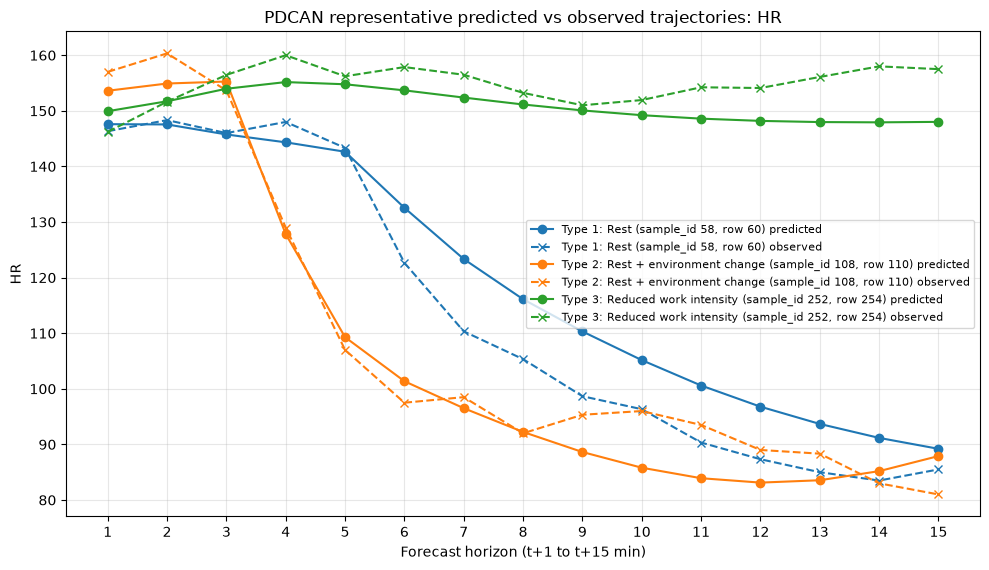

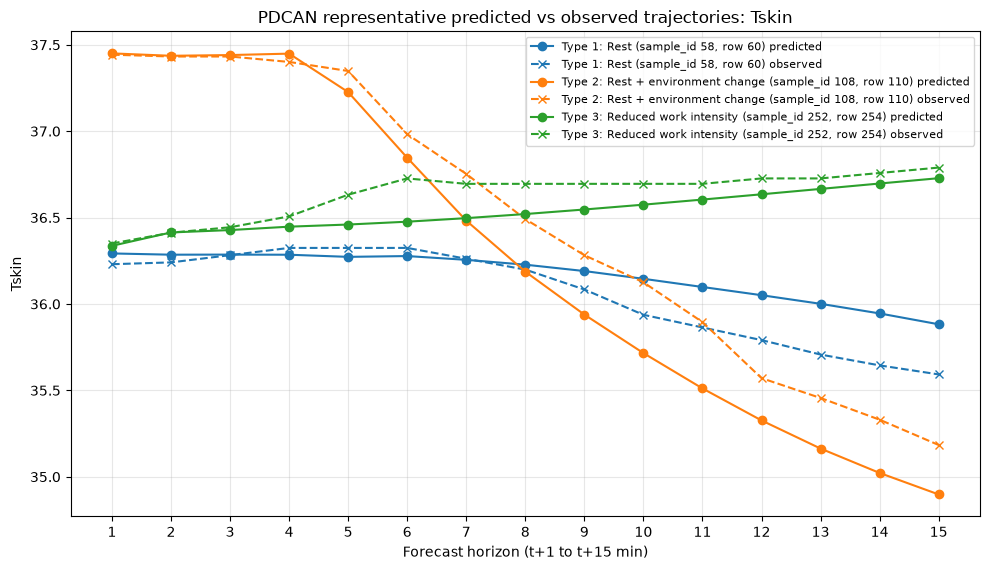

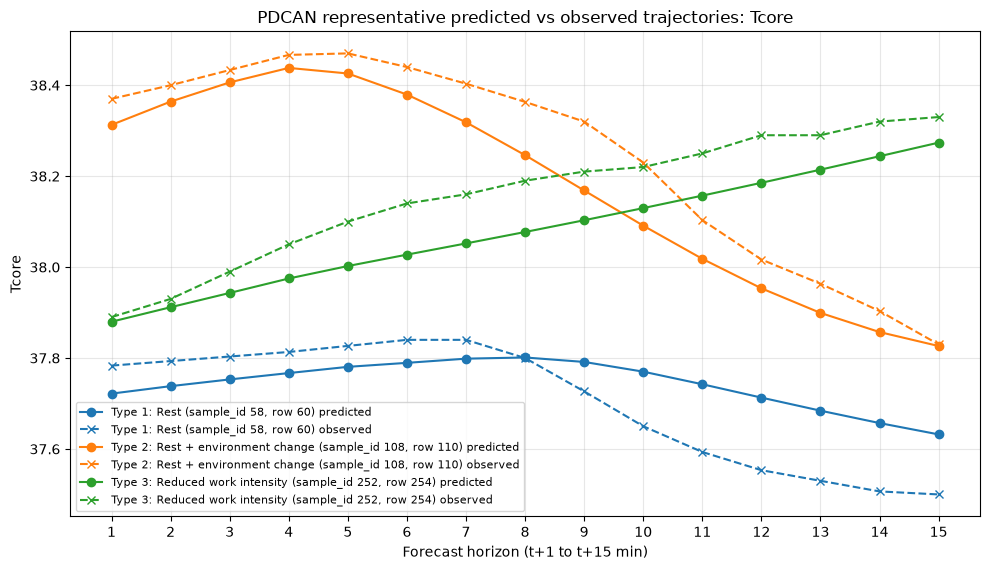

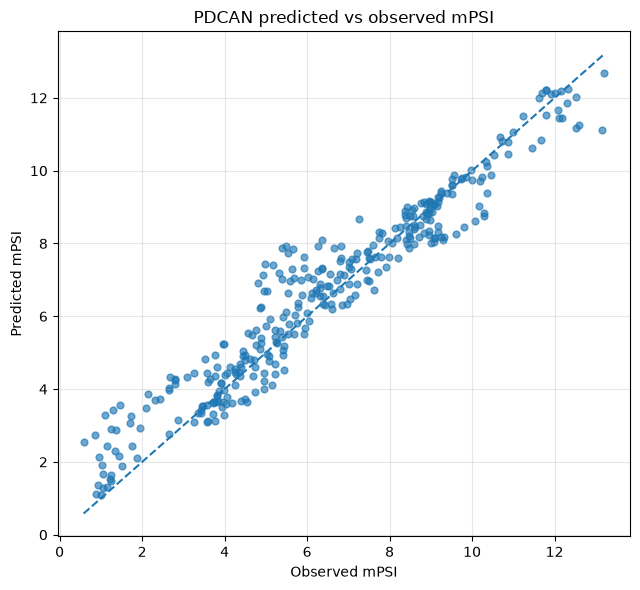

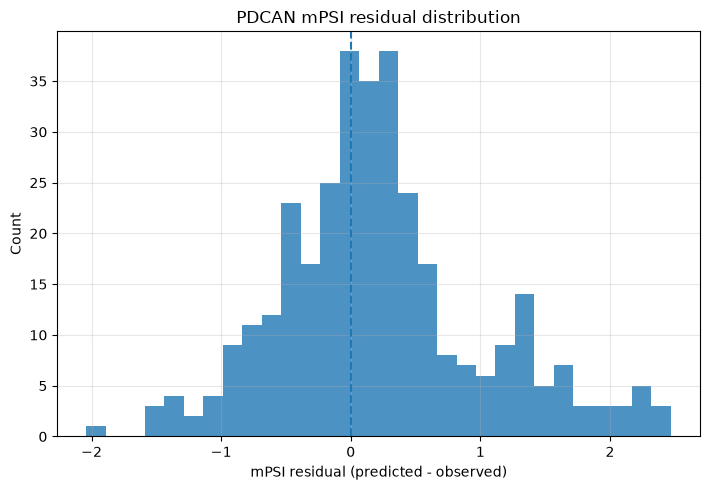


PDCAN 测试集 type=1/2/3 分类型结果：


,type,n_samples,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI
0,1,96,7.308096,9.891640,0.885491,3.791939,0.167185,0.211390,0.776844,0.082943,0.068541,0.090444,0.874776,-0.011290,0.776615,0.973526,0.708574,0.718174
1,2,144,3.720860,5.348597,0.965907,0.418986,0.207354,0.282990,0.933371,-0.118426,0.064191,0.086207,0.921388,0.010430,0.395074,0.517873,0.960363,-0.096765
2,3,96,5.664252,8.708144,0.832533,1.623226,0.125724,0.167117,0.860743,-0.043111,0.073746,0.092708,0.884413,-0.003666,0.736470,1.003783,0.704040,0.215943



PDCAN type=1/2/3 代表性样本：


,array_index,sample_id,source_row,type,MAE_HR,MAE_Tskin,MAE_Tcore,ME_HR,ME_Tskin,ME_Tcore,ABSERR_mPSI,ME_mPSI,score_MAE_HR,score_MAE_Tskin,score_MAE_Tcore,score_ABSERR_mPSI,representative_score
0,58.0,58.0,60.0,1.0,6.705954,0.131789,0.085518,5.988101,0.112518,0.038639,0.876862,0.876862,0.006789,0.044823,0.061350,0.016662,0.129624
1,108.0,108.0,110.0,2.0,4.412630,0.211307,0.067244,-2.133313,-0.202229,-0.067244,0.290035,0.290035,0.034565,0.000364,0.002263,0.070687,0.107879
2,252.0,252.0,254.0,3.0,4.387373,0.101433,0.078949,-3.880771,-0.101272,-0.078949,0.699228,-0.699228,0.050818,0.037331,0.004978,0.002557,0.095684


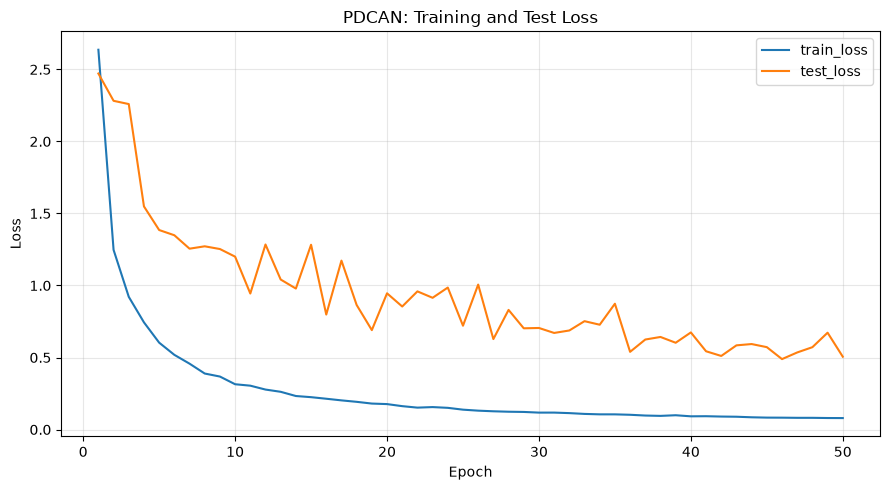

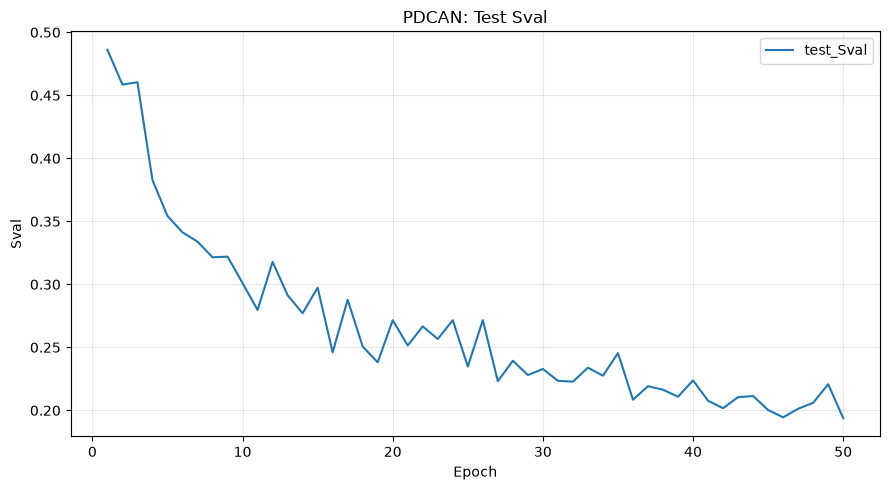

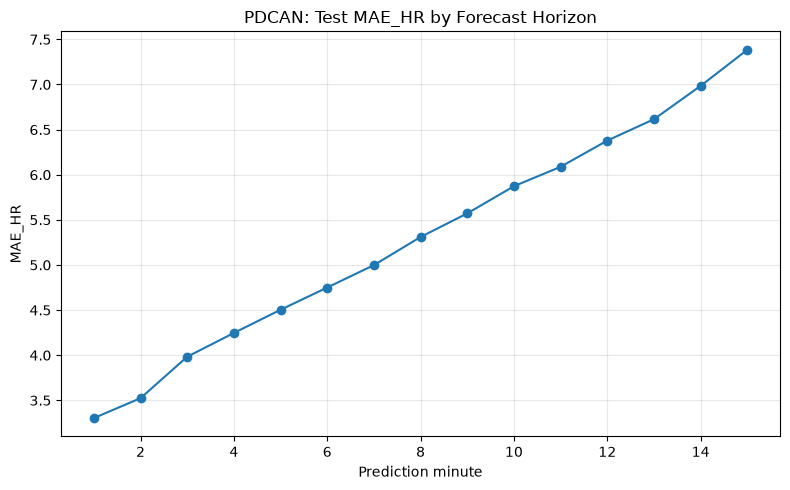

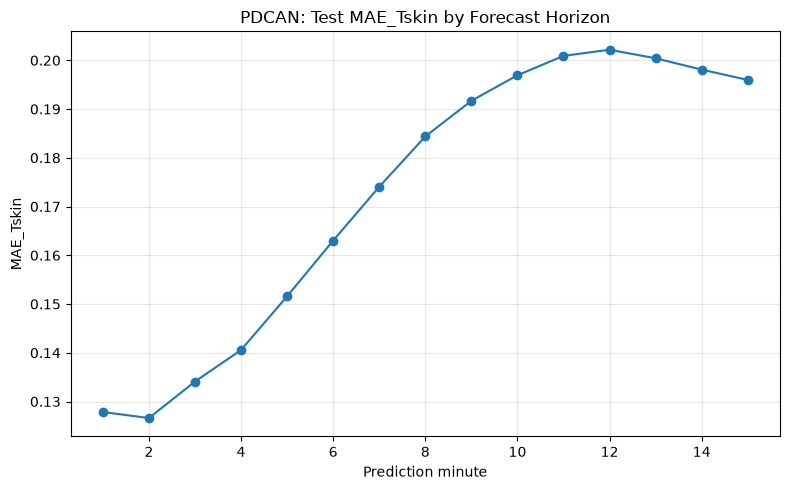

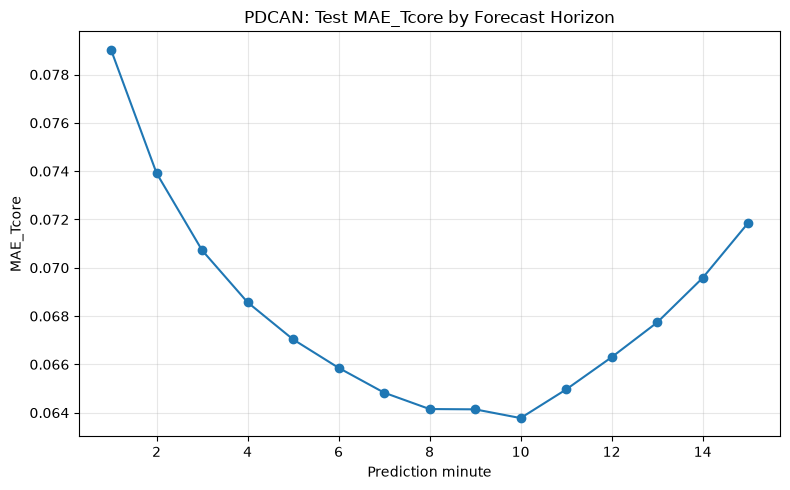


PDCAN 固定轮次最终测试结果：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,PDCAN,50,0.50565,5.301039,7.866521,0.925325,1.726755,0.172554,0.234666,0.942934,-0.039374,0.068164,0.089319,0.937685,0.000197,0.601628,0.820735,0.919855,0.22542,0.193877


In [14]:
result_pdcan = train_and_evaluate_model(
    "PDCAN",
    BEST_HYPERPARAMS["PDCAN"],
    train_data,
    test_data,
    scalers,
    fixed_epochs=FIXED_EPOCHS["PDCAN"],
)
model_results["PDCAN"] = result_pdcan

# 避免重复运行该单元格导致 results 中重复追加
results = [r for name, r in model_results.items()]


In [15]:
# ## 训练并评估 LSTM autoregressive baseline
#
# 使用验证阶段选出的 LSTM 最优超参数和固定训练轮次。


开始训练模型：LSTM
固定训练轮次：37
{
  "lr": 0.0005,
  "weight_decay": 1e-05,
  "batch_size": 128,
  "alpha_hr": 1.5,
  "alpha_tskin": 1.5,
  "alpha_tcore": 1.0,
  "lambda_phys": 1.0,
  "lambda_mpsi": 1.0,
  "lambda_smooth": 0.0,
  "tf_start": 0.8,
  "tf_end": 0.1,
  "encoder_hidden_dims": [
    64
  ],
  "decoder_hidden_dims": [
    128
  ],
  "dropout": 0.1,
  "activation": "silu"
}
LSTM | Epoch 001/037 | train_loss 2.3167 | test_loss 2.3974 | Sval 0.6001 | MAE_mPSI 1.9326 RMSE_mPSI 2.3501 R2_mPSI 0.3429 ME_mPSI 0.8605 | MAE_HR 11.9734 RMSE_HR 15.2320 R2_HR 0.7200 ME_HR 3.5050 | MAE_Tskin 0.4626 RMSE_Tskin 0.5784 R2_Tskin 0.6533 ME_Tskin -0.0265 | MAE_Tcore 0.2824 RMSE_Tcore 0.3505 R2_Tcore 0.0407 ME_Tcore 0.1369 | tf 0.800
LSTM | Epoch 002/037 | train_loss 0.3343 | test_loss 1.7723 | Sval 0.5119 | MAE_mPSI 1.7499 RMSE_mPSI 2.0761 R2_mPSI 0.4872 ME_mPSI 0.8723 | MAE_HR 9.9976 RMSE_HR 13.5549 R2_HR 0.7783 ME_HR 2.2570 | MAE_Tskin 0.3022 RMSE_Tskin 0.4149 R2_Tskin 0.8216 ME_Tskin -0.0283 | MAE_Tco

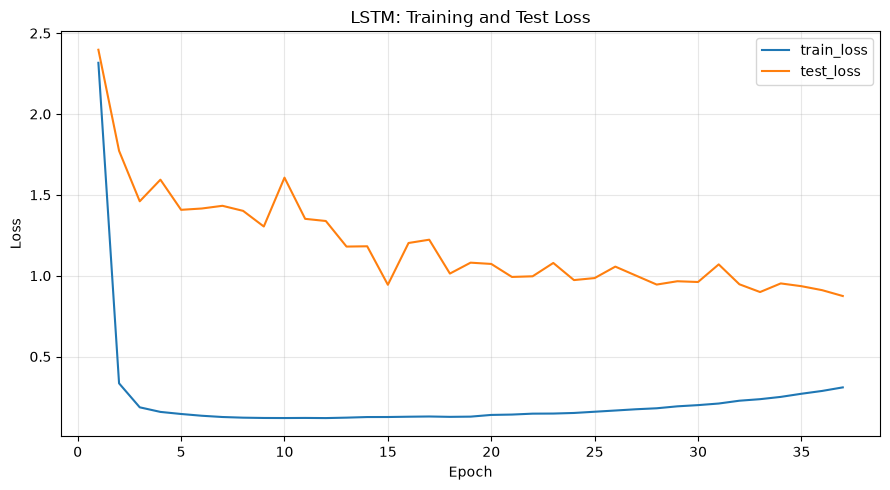

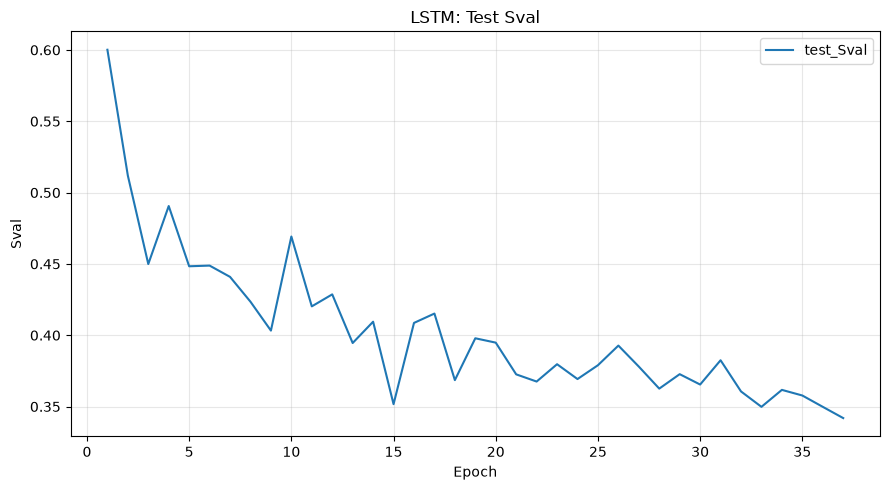

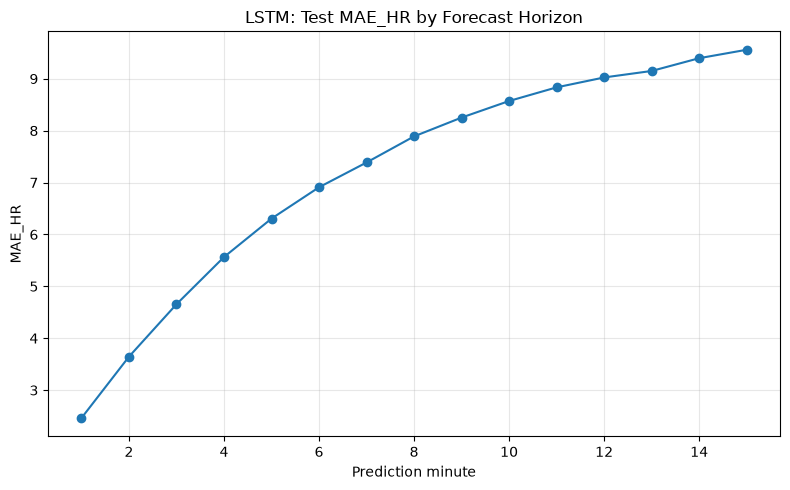

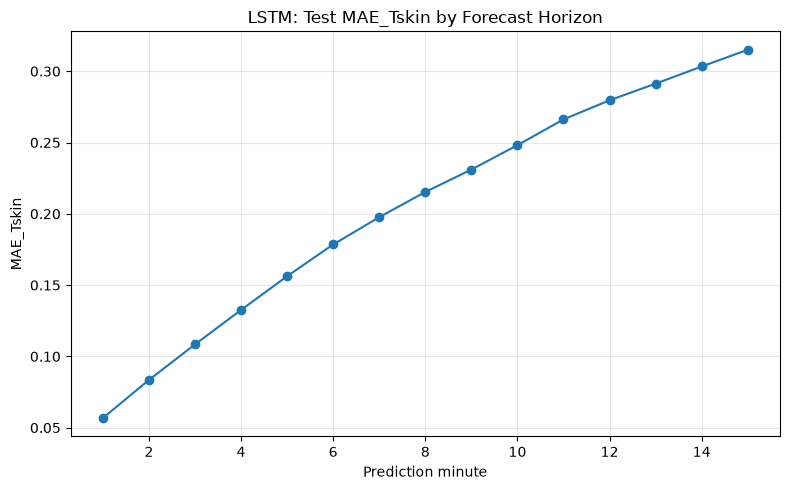

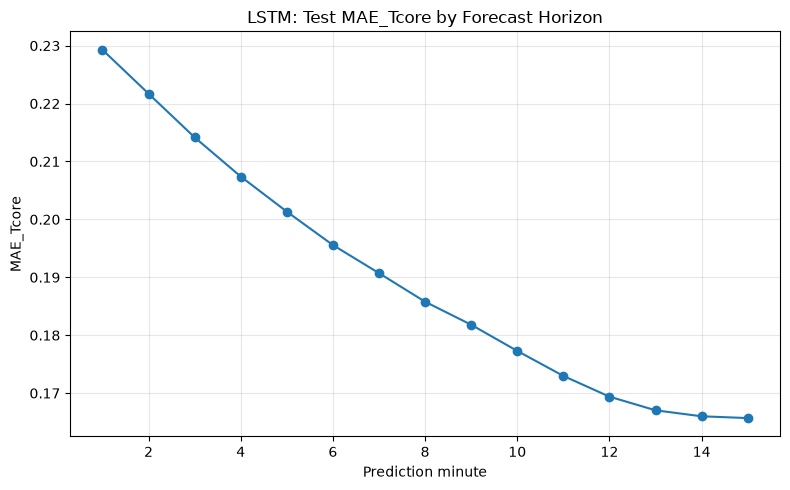


LSTM 固定轮次最终测试结果：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,LSTM,37,0.874308,7.173306,10.230075,0.87371,1.512493,0.204237,0.277525,0.920185,-0.010644,0.189744,0.230962,0.583333,0.046182,1.057995,1.309358,0.796021,0.158676,0.341924


In [16]:
result_lstm = train_and_evaluate_model(
    "LSTM",
    BEST_HYPERPARAMS["LSTM"],
    train_data,
    test_data,
    scalers,
    fixed_epochs=FIXED_EPOCHS["LSTM"],
)
model_results["LSTM"] = result_lstm

# 避免重复运行该单元格导致 results 中重复追加
results = [r for name, r in model_results.items()]

In [17]:
# ## 训练并评估 Transformer autoregressive baseline
#
# 使用验证阶段选出的 Transformer 最优超参数和固定训练轮次。


开始训练模型：Transformer
固定训练轮次：25
{
  "lr": 0.001,
  "weight_decay": 0.0001,
  "batch_size": 128,
  "alpha_hr": 1.5,
  "alpha_tskin": 1.0,
  "alpha_tcore": 1.5,
  "lambda_phys": 1.0,
  "lambda_mpsi": 2.0,
  "lambda_smooth": 0.0,
  "tf_start": 0.8,
  "tf_end": 0.1,
  "d_model": 64,
  "nhead": 8,
  "num_encoder_layers": 3,
  "num_decoder_layers": 2,
  "dim_feedforward": 256,
  "dropout": 0.1,
  "activation": "relu"
}
Transformer | Epoch 001/025 | train_loss 0.9536 | test_loss 4.0448 | Sval 0.6371 | MAE_mPSI 2.3471 RMSE_mPSI 2.8309 R2_mPSI 0.0465 ME_mPSI 1.4165 | MAE_HR 13.0998 RMSE_HR 18.4022 R2_HR 0.5913 ME_HR 8.9535 | MAE_Tskin 0.3532 RMSE_Tskin 0.4848 R2_Tskin 0.7564 ME_Tskin 0.0214 | MAE_Tcore 0.2527 RMSE_Tcore 0.3130 R2_Tcore 0.2345 ME_Tcore 0.1149 | tf 0.800
Transformer | Epoch 002/025 | train_loss 0.3399 | test_loss 2.6643 | Sval 0.5162 | MAE_mPSI 1.6750 RMSE_mPSI 2.0763 R2_mPSI 0.4871 ME_mPSI -0.3221 | MAE_HR 11.4060 RMSE_HR 16.2207 R2_HR 0.6825 ME_HR 4.1077 | MAE_Tskin 0.3843 RMSE_T

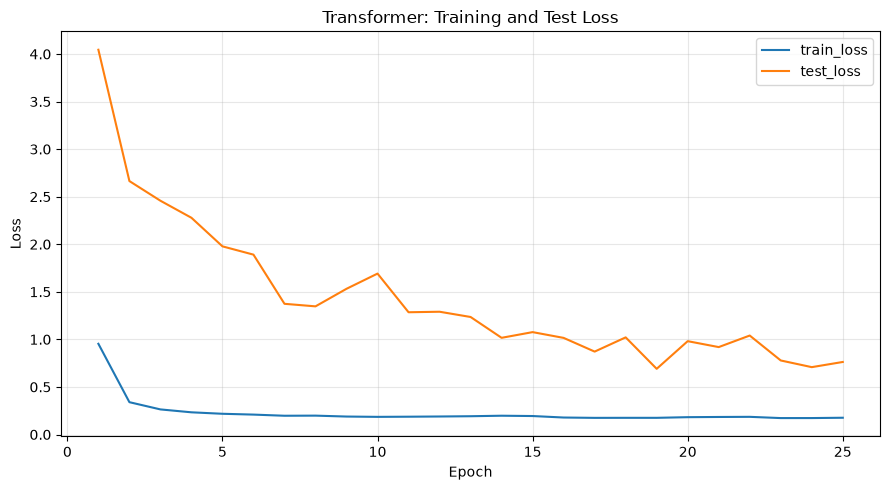

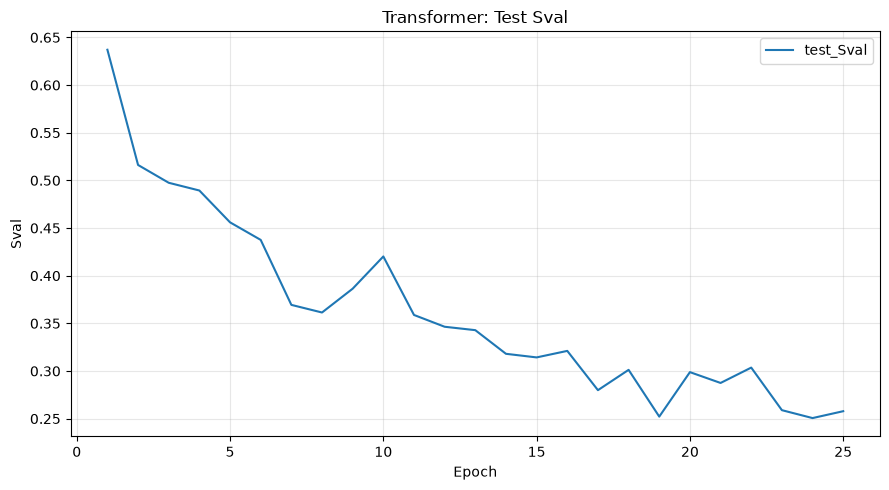

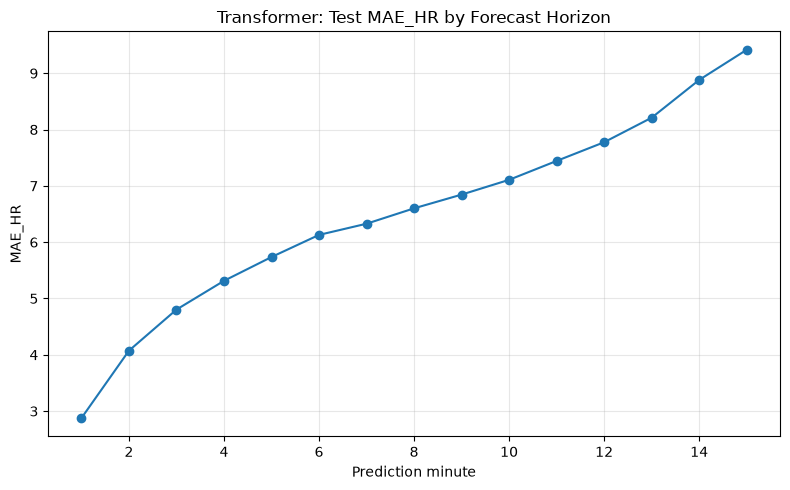

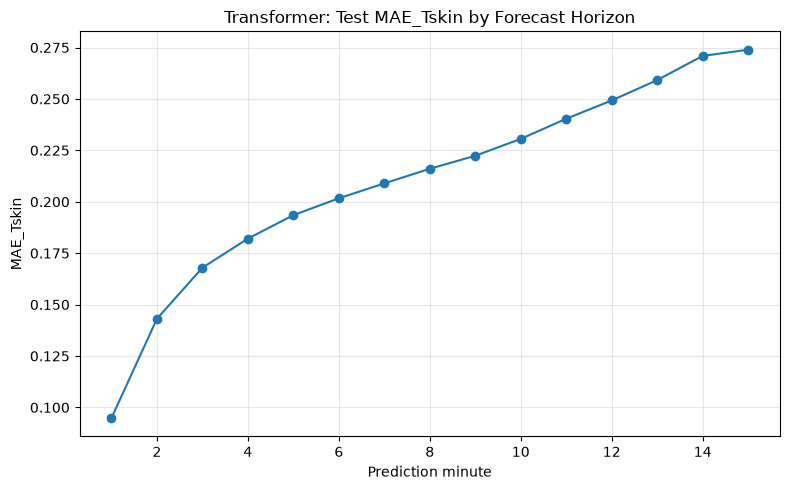

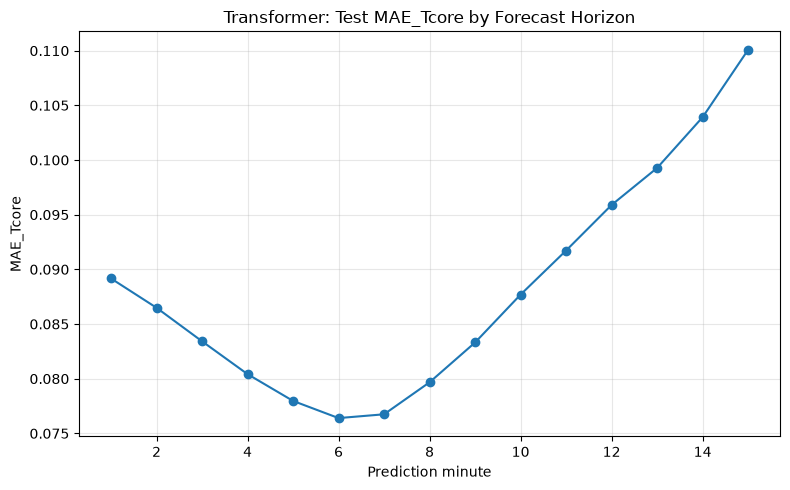


Transformer 固定轮次最终测试结果：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,Transformer,25,0.762624,6.502707,9.450009,0.892236,2.201421,0.210308,0.299968,0.906755,-0.066618,0.088146,0.116211,0.894513,-0.004824,0.857995,1.165269,0.838445,0.198875,0.257843


In [18]:
result_transformer = train_and_evaluate_model(
    "Transformer",
    BEST_HYPERPARAMS["Transformer"],
    train_data,
    test_data,
    scalers,
    fixed_epochs=FIXED_EPOCHS["Transformer"],
)
model_results["Transformer"] = result_transformer

# 避免重复运行该单元格导致 results 中重复追加
results = [r for name, r in model_results.items()]

In [19]:
# ## 训练并评估 GRU autoregressive baseline
#
# 使用验证阶段选出的 GRU 最优超参数和固定训练轮次。


开始训练模型：GRU
固定训练轮次：47
{
  "lr": 0.0003,
  "weight_decay": 0.0001,
  "batch_size": 128,
  "alpha_hr": 1.0,
  "alpha_tskin": 1.5,
  "alpha_tcore": 1.0,
  "lambda_phys": 1.0,
  "lambda_mpsi": 3.0,
  "lambda_smooth": 0.0,
  "tf_start": 0.8,
  "tf_end": 0.05,
  "encoder_hidden_dims": [
    64
  ],
  "decoder_hidden_dims": [
    128
  ],
  "dropout": 0.2,
  "activation": "gelu"
}
GRU | Epoch 001/047 | train_loss 2.9426 | test_loss 2.8663 | Sval 0.5380 | MAE_mPSI 1.5804 RMSE_mPSI 1.9279 R2_mPSI 0.5578 ME_mPSI 0.2101 | MAE_HR 14.0769 RMSE_HR 16.7454 R2_HR 0.6616 ME_HR 1.9306 | MAE_Tskin 0.3762 RMSE_Tskin 0.4905 R2_Tskin 0.7507 ME_Tskin -0.0754 | MAE_Tcore 0.2624 RMSE_Tcore 0.3206 R2_Tcore 0.1973 ME_Tcore 0.0625 | tf 0.800
GRU | Epoch 002/047 | train_loss 0.5237 | test_loss 2.8958 | Sval 0.5180 | MAE_mPSI 1.6455 RMSE_mPSI 2.0592 R2_mPSI 0.4955 ME_mPSI 0.1282 | MAE_HR 11.1932 RMSE_HR 14.2432 R2_HR 0.7552 ME_HR 1.1004 | MAE_Tskin 0.3437 RMSE_Tskin 0.4507 R2_Tskin 0.7895 ME_Tskin -0.0625 | MAE_Tco

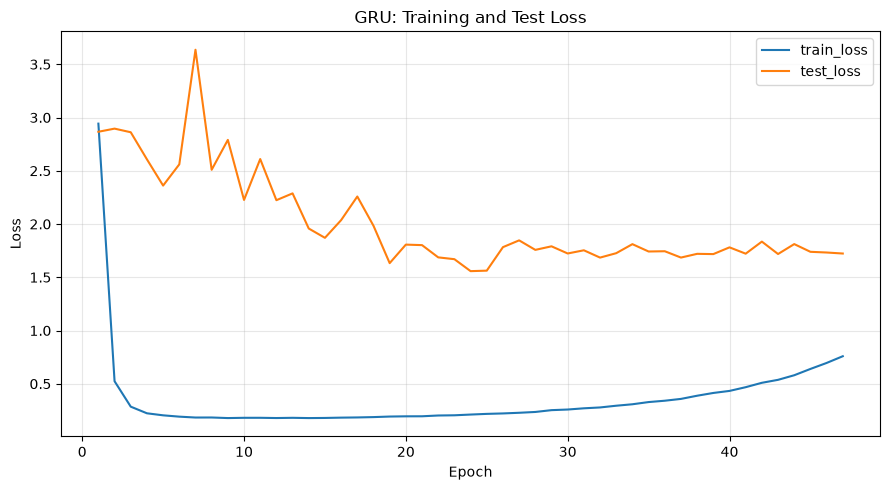

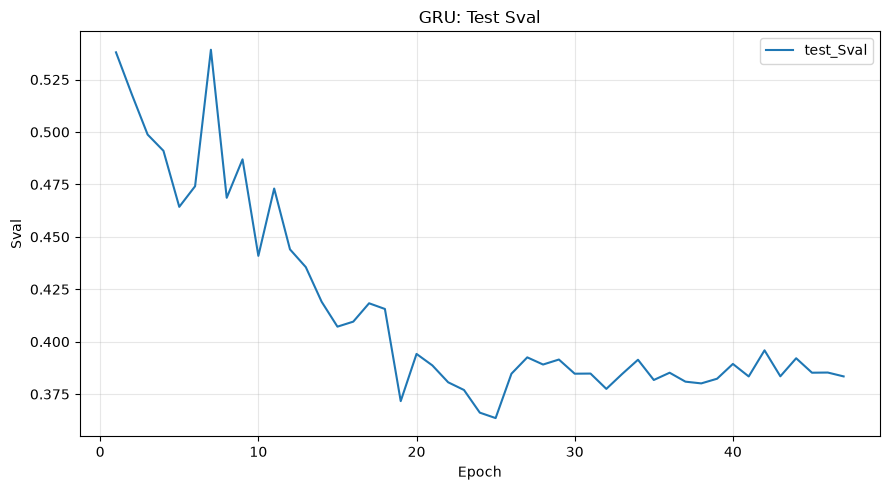

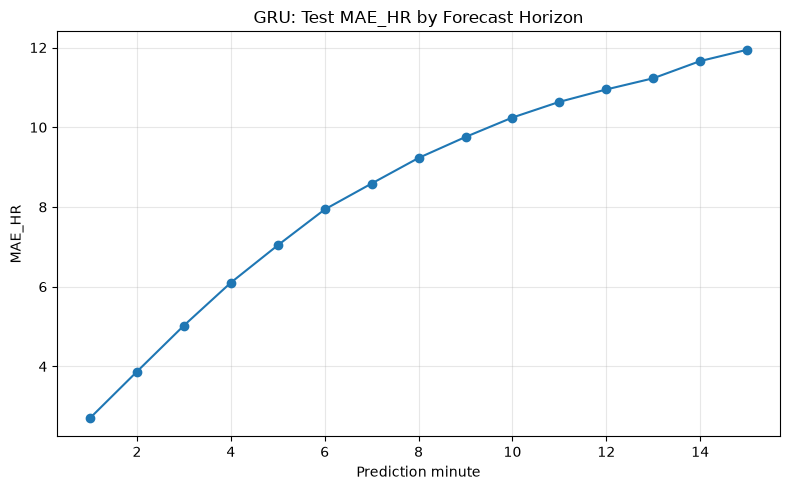

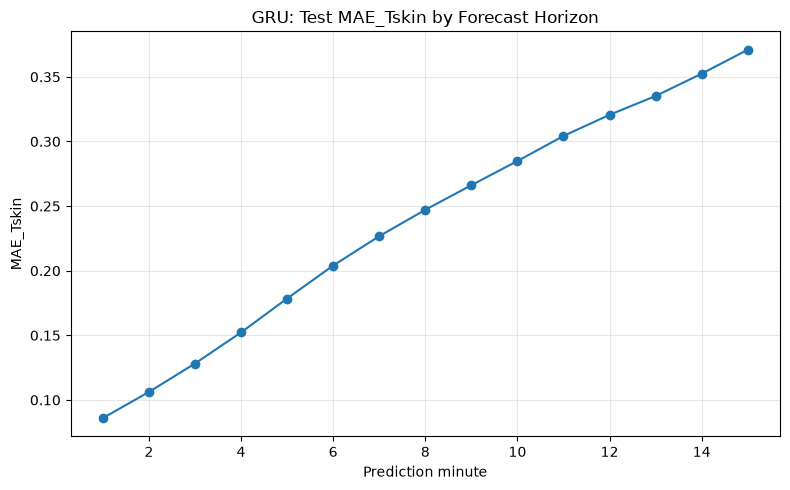

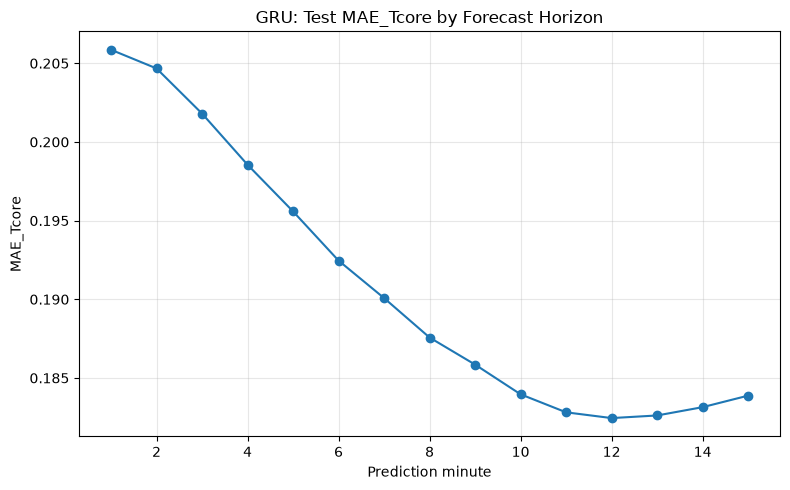


GRU 固定轮次最终测试结果：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,GRU,47,1.723002,8.461287,11.960376,0.827377,2.45097,0.237569,0.326007,0.889863,-0.07647,0.190754,0.238966,0.553955,0.047768,1.228052,1.578025,0.703724,0.28554,0.383444


In [20]:
result_gru = train_and_evaluate_model(
    "GRU",
    BEST_HYPERPARAMS["GRU"],
    train_data,
    test_data,
    scalers,
    fixed_epochs=FIXED_EPOCHS["GRU"],
)
model_results["GRU"] = result_gru

# 避免重复运行该单元格导致 results 中重复追加
results = [r for name, r in model_results.items()]

In [21]:
# ## 汇总PDCAN 与三个基线模型测试集结果
#
# 运行完上面四个训练单元格后执行本单元格，生成并保存总表。

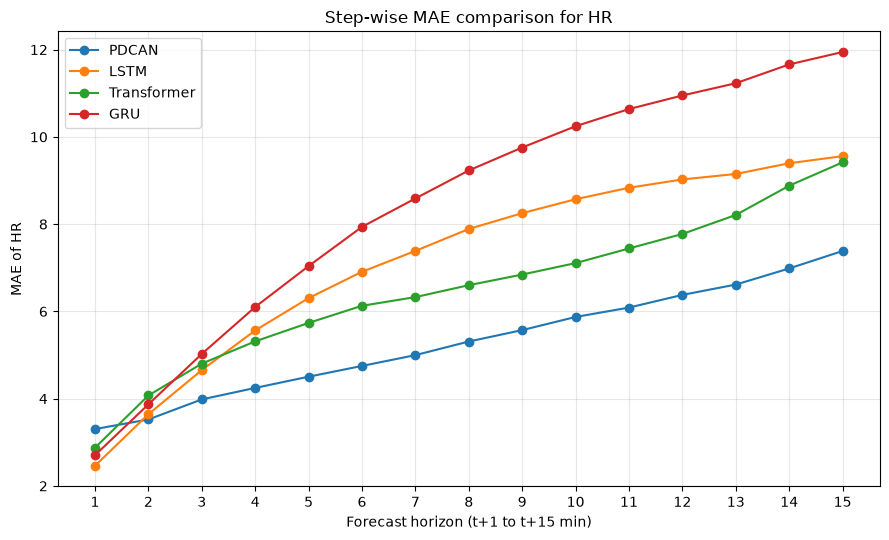

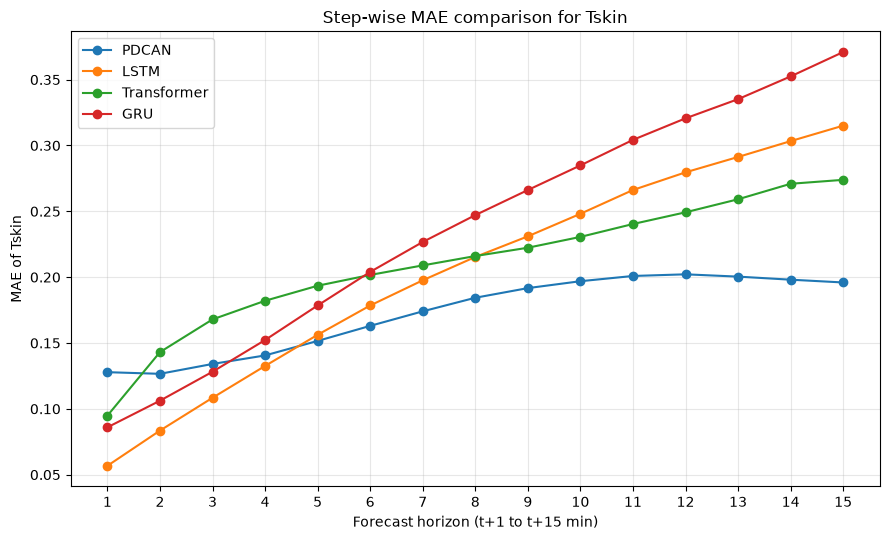

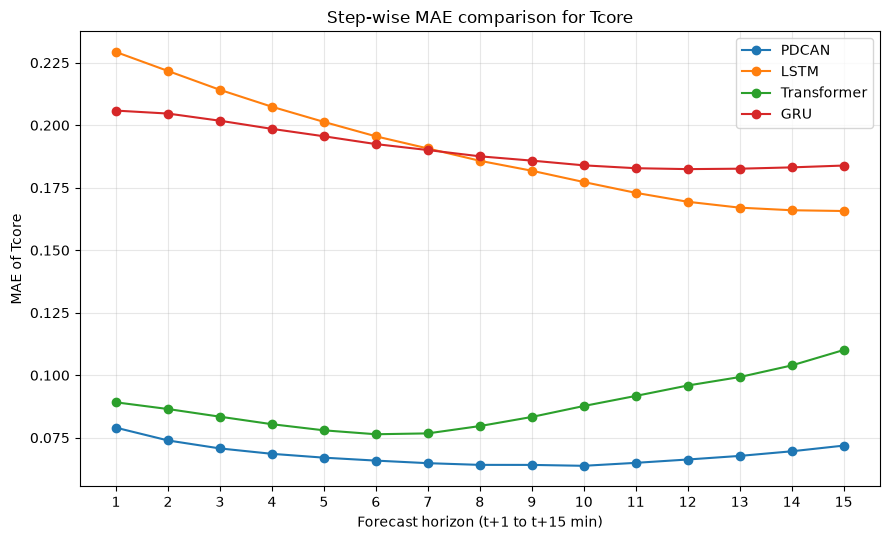


PDCAN 与三个基线模型最终测试集结果汇总：


,model,trained_epochs,test_loss,MAE_HR,RMSE_HR,R2_HR,ME_HR,MAE_Tskin,RMSE_Tskin,R2_Tskin,ME_Tskin,MAE_Tcore,RMSE_Tcore,R2_Tcore,ME_Tcore,MAE_mPSI,RMSE_mPSI,R2_mPSI,ME_mPSI,Sval
0,PDCAN,50,0.505650,5.301039,7.866521,0.925325,1.726755,0.172554,0.234666,0.942934,-0.039374,0.068164,0.089319,0.937685,0.000197,0.601628,0.820735,0.919855,0.225420,0.193877
2,Transformer,25,0.762624,6.502707,9.450009,0.892236,2.201421,0.210308,0.299968,0.906755,-0.066618,0.088146,0.116211,0.894513,-0.004824,0.857995,1.165269,0.838445,0.198875,0.257843
1,LSTM,37,0.874308,7.173306,10.230075,0.873710,1.512493,0.204237,0.277525,0.920185,-0.010644,0.189744,0.230962,0.583333,0.046182,1.057995,1.309358,0.796021,0.158676,0.341924
3,GRU,47,1.723002,8.461287,11.960376,0.827377,2.450970,0.237569,0.326007,0.889863,-0.076470,0.190754,0.238966,0.553955,0.047768,1.228052,1.578025,0.703724,0.285540,0.383444



结果已保存到： ./final_test_fixed_epoch_all_models_PDCAN_outputs


In [22]:
if len(model_results) == 0:
    raise RuntimeError("还没有任何模型结果。请先运行至少一个模型训练单元格。")

# 四个模型的 t+1 到 t+15 MAE 对比折线图，分别输出 HR、Tskin、Tcore。
plot_all_models_step_mae(model_results, OUTPUT_DIR)

summary_df = pd.DataFrame([r["summary_row"] for r in model_results.values()]).sort_values("Sval")
summary_path_csv = os.path.join(OUTPUT_DIR, "final_test_summary_all_models.csv")
summary_path_xlsx = os.path.join(OUTPUT_DIR, "final_test_summary_all_models.xlsx")
summary_df.to_csv(summary_path_csv, index=False, encoding="utf-8-sig")
try:
    summary_df.to_excel(summary_path_xlsx, index=False)
except Exception as e:
    print("保存 Excel 失败，仅保留 CSV。错误：", repr(e))

print("\nPDCAN 与三个基线模型最终测试集结果汇总：")
display(summary_df)
print("\n结果已保存到：", OUTPUT_DIR)

## Notes

This notebook preserves the original LSTM, GRU, and Transformer baseline architectures, hyperparameters, fixed epochs, training logic, evaluation metrics, and plotting routines. The previous main model slot is replaced by PDCAN, the selected no-autoregressive-feedback architecture.
